# IoT Device Classification: JA4+
## Random Forest vs. CatBoost vs. Dictionary Matching on UNSW-IoTraffic and CIC-IoT-2023

### HW & SW definition

In [10]:
# --- REPRODUCIBILITY, HARDWARE CAPABILITIES & SOFTWARE ENVIRONMENT REPORT ---
# Automatically extracts hardware limitations (CPU frequencies, threads, RAM), 
# OS/WSL environment, and core ML model versions (Random Forest / CatBoost) for academic reporting.
import sys
import platform
import psutil
import os
import pandas as pd
import numpy as np
import sklearn
import catboost
import statsmodels

def get_complete_environment_specs():
    specs = {}
    
    # 1. Hardware Capabilities & Limitations (CPU & RAM constraints)
    uname = platform.uname()
    specs["Machine Architecture"] = uname.machine
    specs["Processor Type"] = uname.processor if uname.processor else platform.processor()
    specs["Physical CPU Cores"] = psutil.cpu_count(logical=False)
    specs["Logical CPU Cores (Threads)"] = psutil.cpu_count(logical=True)
    
    cpu_freq = psutil.cpu_freq()
    if cpu_freq:
        specs["CPU Current Frequency"] = f"{cpu_freq.current:.2f} MHz"
        specs["CPU Max Frequency"] = f"{cpu_freq.max:.2f} MHz" if cpu_freq.max else "N/A"
        specs["CPU Min Frequency"] = f"{cpu_freq.min:.2f} MHz" if cpu_freq.min else "N/A"
        
    ram = psutil.virtual_memory()
    specs["Total System RAM"] = f"{ram.total / (1024**3):.2f} GB"
    specs["Available System RAM"] = f"{ram.available / (1024**3):.2f} GB"
    specs["Current RAM Usage"] = f"{ram.percent}%"
    
    # 2. OS & WSL / Ubuntu Details
    specs["Base OS Platform"] = platform.system()
    specs["OS Release"] = platform.release()
    specs["OS Version"] = platform.version()
    
    # Check for Linux / WSL distribution release file
    if os.path.exists("/etc/os-release"):
        try:
            with open("/etc/os-release", "r") as f:
                for line in f:
                    if line.startswith("PRETTY_NAME="):
                        specs["Linux/WSL Distribution"] = line.split("=")[1].strip().strip('"')
        except Exception:
            pass
            
    # Check kernel version to identify WSL signature
    if os.path.exists("/proc/version"):
        try:
            with open("/proc/version", "r") as f:
                kernel_info = f.read().strip()
                specs["Kernel Version"] = kernel_info
                if "microsoft" in kernel_info.lower() or "wsl" in kernel_info.lower():
                    specs["Execution Environment"] = "WSL (Windows Subsystem for Linux)"
                else:
                    specs["Execution Environment"] = "Native Linux / Bare Metal"
        except Exception:
            pass
    else:
        specs["Execution Environment"] = "Windows Native Host"
        
    # 3. Software Stack & Model Engine Versions
    specs["Python Version"] = sys.version.split()[0]
    specs["Random Forest Engine (Scikit-Learn)"] = sklearn.__version__
    specs["CatBoost Version"] = catboost.__version__
    specs["Statsmodels Version"] = statsmodels.__version__
    specs["Pandas Version"] = pd.__version__
    specs["NumPy Version"] = np.__version__
    
    return specs

full_env_metadata = get_complete_environment_specs()

print("=" * 80)
print("COMPLETE EXPERIMENTAL SETUP REPORT")
print("=" * 80)
for key, value in full_env_metadata.items():
    print(f" • {key}: {value}")
print("=" * 80)

COMPLETE EXPERIMENTAL SETUP REPORT
 • Machine Architecture: AMD64
 • Processor Type: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
 • Physical CPU Cores: 4
 • Logical CPU Cores (Threads): 8
 • CPU Current Frequency: 1803.00 MHz
 • CPU Max Frequency: 2304.00 MHz
 • CPU Min Frequency: N/A
 • Total System RAM: 15.71 GB
 • Available System RAM: 1.72 GB
 • Current RAM Usage: 89.1%
 • Base OS Platform: Windows
 • OS Release: 11
 • OS Version: 10.0.26200
 • Execution Environment: Windows Native Host
 • Python Version: 3.13.14
 • Random Forest Engine (Scikit-Learn): 1.8.0
 • CatBoost Version: 1.2.10
 • Statsmodels Version: 0.15.0
 • Pandas Version: 3.0.2
 • NumPy Version: 2.4.4


### Purpose and representation
This notebook evaluates the complete JA4+ fingerprint family using the compact signatures and their decomposed fields. The active signature and feature lists are defined explicitly in the configuration cell for this combination.

The **Full** representation uses every compact signature in `FULL_FEATURES`. The **Decomposed** representation uses only the protocol-level fields listed in `DECOMPOSED_FEATURES`, split into numeric and categorical features for preprocessing.

Rows are retained only when all signatures in `SIGNATURE_COLUMNS` are present and valid. Both representations use the same per-device train/test split and are evaluated with Dictionary Matching, Random Forest and CatBoost on UNSW-IoTraffic and CIC-IoT-2023.

In [1]:
import os
import time
import sys
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    top_k_accuracy_score,
    classification_report,
    make_scorer,
)
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import ttest_rel

from catboost import CatBoostClassifier

pd.set_option("display.float_format", lambda value: f"{value:.4f}")

DATASETS_CONFIG = {
    "UNSW": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\unsw_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    },
    "CIC_IOT": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\cic_iot_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    }
}

OUTPUT_DIR = r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados"
os.makedirs(OUTPUT_DIR, exist_ok=True)
EXCEL_PATH = os.path.join(OUTPUT_DIR, "Comparativa_Modelos_Avanzada_JA4_PLUS.xlsx")

## 1. Exploratory Data Analysis, Fingerprint Inspection, and Filtering Audit

This section reports the sample and device-class counts before and after filtering. It displays the complete compact signature bundle from `FULL_FEATURES` alongside the decomposed fields in `DECOMPOSED_FEATURES`. A row is valid only when every signature in `SIGNATURE_COLUMNS` is present. Classes with fewer than `min_samples=5` observations are excluded, and retained classes are reproducibly capped at `max_samples=500` using seed 42.

Fingerprint repetition is measured for the complete selected bundle:

$$
Repeated\ fingerprints = Valid\ samples - Unique\ fingerprint\ bundles
$$

In [2]:
# Feature groups for the complete JA4+ fingerprint family.
COMBINATION_NAME = "JA4+"
SIGNATURE_COLUMNS = ["ja4", "ja4s", "ja4t", "ja4ts", "ja4x"]
DECOMPOSED_FEATURES = [
    "ja4_protocol","ja4_tls_version", "ja4_sni_type", "ja4_n_ciphers", "ja4_n_extensions",
    "ja4_alpn", "ja4_cipher_hash", "ja4_extension_hash",
    "ja4s_protocol", "ja4s_tls_version", "ja4s_n_extensions", "ja4s_alpn",
    "ja4s_cipher_chosen", "ja4s_extension_hash",
    "ja4t_window_size", "ja4t_option_list", "ja4t_mss", "ja4t_scale",
    "ja4t_num_options", "ja4t_has_timestamp", "ja4t_has_sack",
    "ja4t_has_window_scale",
    "ja4ts_window_size", "ja4ts_option_list", "ja4ts_mss", "ja4ts_scale",
    "ja4ts_num_options", "ja4ts_has_timestamp", "ja4ts_has_sack",
    "ja4ts_has_window_scale",
    "ja4x_issuer_hash", "ja4x_subject_hash", "ja4x_extensions_hash"
]
NUMERIC_DECOMPOSED = [
    "ja4_n_ciphers", "ja4_n_extensions", "ja4s_n_extensions",
    "ja4t_window_size", "ja4t_mss", "ja4t_scale", "ja4t_num_options",
    "ja4t_has_timestamp", "ja4t_has_sack", "ja4t_has_window_scale",
    "ja4ts_window_size", "ja4ts_mss", "ja4ts_scale", "ja4ts_num_options",
    "ja4ts_has_timestamp", "ja4ts_has_sack", "ja4ts_has_window_scale"
]
CATEGORICAL_DECOMPOSED = [c for c in DECOMPOSED_FEATURES if c not in NUMERIC_DECOMPOSED]
FULL_FEATURES = SIGNATURE_COLUMNS.copy()
TARGET_COL = "device_name"


def analyze_and_clean_dataset(csv_path, min_samples=5, max_samples=500, dataset_name="Dataset"):
    print("=" * 80)
    print(f"EXPLORATORY AUDIT & FILTERING ANALYSIS: {COMBINATION_NAME} | {dataset_name}")
    print("=" * 80)

    df_raw = pd.read_csv(csv_path, dtype=str, low_memory=False)
    init_samples = len(df_raw)
    init_classes = df_raw[TARGET_COL].nunique()

    valid_mask = pd.Series(True, index=df_raw.index)
    for column in SIGNATURE_COLUMNS:
        values = df_raw[column].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])
    df_valid = df_raw[valid_mask].copy()

    df_valid["fingerprint_bundle"] = df_valid[FULL_FEATURES].agg(" | ".join, axis=1)
    total_fingerprints = len(df_valid)
    unique_fingerprints = df_valid["fingerprint_bundle"].nunique()
    repeated_fingerprints = total_fingerprints - unique_fingerprints

    print(f"[Fingerprint Stats] Total valid samples: {total_fingerprints}")
    print(f"[Fingerprint Stats] Unique {COMBINATION_NAME} fingerprints: {unique_fingerprints} ({unique_fingerprints/total_fingerprints*100:.2f}%)")
    print(f"[Fingerprint Stats] Repeated {COMBINATION_NAME} fingerprints: {repeated_fingerprints} ({repeated_fingerprints/total_fingerprints*100:.2f}%)")

    print("\n--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---")
    sample_columns = [TARGET_COL] + FULL_FEATURES + DECOMPOSED_FEATURES
    display(df_valid[sample_columns].head(3))

    dev_counts = df_valid[TARGET_COL].value_counts()
    dropped_classes = dev_counts[dev_counts < min_samples].index.tolist()
    retained_devices = dev_counts[dev_counts >= min_samples].index
    df_filtered = df_valid[df_valid[TARGET_COL].isin(retained_devices)].copy()

    if max_samples:
        rng = np.random.default_rng(42)
        df_filtered = df_filtered.assign(_random_order=rng.random(len(df_filtered)))
        df_filtered = (
            df_filtered.sort_values([TARGET_COL, "_random_order"])
            .groupby(TARGET_COL, group_keys=False)
            .head(max_samples)
            .drop(columns="_random_order")
            .reset_index(drop=True)
        )
    final_samples = len(df_filtered)
    final_classes = df_filtered[TARGET_COL].nunique()

    audit_summary = {
        "Dataset": dataset_name,
        "Initial Samples": init_samples,
        "Valid Samples (Pre-filter)": total_fingerprints,
        "Filtered Samples (Post-min/max)": final_samples,
        "Initial Classes": init_classes,
        "Retained Classes": final_classes,
        "Dropped Classes Count": len(dropped_classes),
        "Dropped Classes List": str(dropped_classes)
    }

    print(f"[Audit Summary] Retained Classes: {final_classes}/{init_classes} | Final Samples: {final_samples}")
    print("-" * 80)

    for column in NUMERIC_DECOMPOSED:
        df_filtered[column] = pd.to_numeric(df_filtered[column], errors="coerce")
    df_filtered = df_filtered.dropna(subset=NUMERIC_DECOMPOSED).reset_index(drop=True)

    for column in [TARGET_COL] + FULL_FEATURES + CATEGORICAL_DECOMPOSED:
        df_filtered[column] = df_filtered[column].fillna("unknown").astype(str).str.strip().str.lower()

    return df_filtered, audit_summary


def split_data_per_device(df, test_size=0.2, random_state=42):
    train_list, test_list = [], []
    for device in df[TARGET_COL].unique():
        subset = df[df[TARGET_COL] == device]
        if len(subset) < 2:
            train_list.append(subset)
            continue
        train, test = train_test_split(
            subset,
            test_size=test_size,
            random_state=random_state,
            shuffle=True
        )
        train_list.append(train)
        test_list.append(test)
    return pd.concat(train_list, ignore_index=True), pd.concat(test_list, ignore_index=True)

## 2. Dictionary Matching Baseline

The baseline performs exact matching over all compact signature columns in `FULL_FEATURES`. If a fingerprint bundle maps to multiple devices, it selects the most frequent training label. Unseen bundles fall back to the most frequent training class.

In [13]:
class DictionaryMatchingClassifier:
    def __init__(self):
        self.mapping = {}
        self.default_class = None
        self.classes_ = None

    def fit(self, X_df, y_train):
        train_data = X_df[FULL_FEATURES].copy()
        train_data["target"] = np.asarray(y_train)
        grouped = train_data.groupby(FULL_FEATURES)["target"].agg(lambda labels: labels.mode()[0])
        self.mapping = grouped.to_dict()
        self.default_class = pd.Series(y_train).mode()[0]
        self.classes_ = np.unique(np.asarray(y_train))

    def predict(self, X_df):
        fingerprints = list(map(tuple, X_df[FULL_FEATURES].to_numpy()))
        return np.asarray([self.mapping.get(fingerprint, self.default_class) for fingerprint in fingerprints])

    def predict_proba(self, X_df):
        class_to_idx = {label: index for index, label in enumerate(self.classes_)}
        probabilities = np.zeros((len(X_df), len(self.classes_)))
        fingerprints = list(map(tuple, X_df[FULL_FEATURES].to_numpy()))
        for index, fingerprint in enumerate(fingerprints):
            matched_class = self.mapping.get(fingerprint, self.default_class)
            probabilities[index, class_to_idx[matched_class]] = 1.0
        return probabilities

## 3. Profiling Pipeline & Statistical Testing Functions

**Read this explanation before executing the next cell.** This section primarily addresses Reviewer 1, Concern 3, about the need for statistical evidence when comparing algorithms, and Reviewer 1, Concern 8 and Reviewer 3, Concern 2, about computational cost.

### What is being compared?

Each model generates a prediction for exactly the same test observations. For every observation, the code creates a correctness indicator:

$$
correct_{model,i} =
\begin{cases}
1 & \text{if the prediction is correct}\\
0 & \text{if the prediction is incorrect}
\end{cases}
$$

The correctness vectors are compared pairwise:

- Dictionary Matching versus Random Forest.
- Dictionary Matching versus CatBoost.
- Random Forest versus CatBoost.

### Macro F1 bootstrap interval

The `bootstrap_ci` function draws 1,000 samples with replacement from the test set. It computes macro F1 for every resample. The 95% confidence interval is obtained from the 2.5th and 97.5th percentiles:

$$
CI_{95\%}(F1) = [P_{2.5}(F1^*), P_{97.5}(F1^*)]
$$

This interval expresses uncertainty in the F1 estimate for the evaluated split. It does not, by itself, prove that one algorithm is better than another.

### Paired t-test

`ttest_rel` compares the correctness indicators of two models on the same observations. The null hypothesis is:

$$
H_0: E(correct_A - correct_B) = 0
$$

The usual interpretation is:

- `p < 0.05`: evidence of a difference in mean correctness.
- `p >= 0.05`: no statistically significant difference is demonstrated.

If both models succeed and fail on exactly the same observations, the difference is constant and its standard deviation is zero. The t-test then returns `NaN`; this must not be interpreted as model superiority or as a model failure.

### McNemar test

McNemar's test is particularly suitable for comparing two classifiers on the same observations. It uses only discordant cases:

- `b`: model A is correct and model B is incorrect.
- `c`: model A is incorrect and model B is correct.

With continuity correction, the statistic is:

$$
\chi^2 = \frac{(|b-c|-1)^2}{b+c}
$$

The null hypothesis is that both models have the same error proportion. If `b + c = 0`, the models do not disagree on any observation and the test has no variation to analyze.

### Resource profiling

The notebook also calculates:

$$
Latency_{sample} = \frac{t_{prediction}}{N},
\qquad
Throughput = \frac{N}{t_{prediction}}
$$

Training time and an RSS-based process-memory estimate are also recorded. These values describe this execution environment and hardware; they are not universal algorithmic constants.

### How to interpret the results

A method should not be selected only because it has the largest F1. The comparison should consider macro F1, confidence intervals, p-values, latency, throughput and memory together. Rows containing `NaN` or `inf` indicate that there was insufficient variation or disagreement to apply the formula, not that the model failed.

In [14]:
def get_process_memory_mb():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

def bootstrap_ci(y_true, y_pred, metric_func, n_bootstraps=1000, alpha=0.05):
    scores = []
    n = len(y_true)
    rng = np.random.default_rng(42)
    for _ in range(n_bootstraps):
        indices = rng.integers(0, n, n)
        if len(np.unique(y_true[indices])) < 2:
            continue
        scores.append(metric_func(y_true[indices], y_pred[indices]))
    if not scores:
        return 0.0, 0.0
    return np.percentile(scores, 100 * (alpha / 2)), np.percentile(scores, 100 * (1 - alpha / 2))

def compare_predictions(y_true, predictions, experiment):
    statistical_results = []
    model_names = list(predictions.keys())
    y_true = np.asarray(y_true)

    for index, model_a in enumerate(model_names):
        for model_b in model_names[index + 1:]:
            correct_a = (np.asarray(predictions[model_a]) == y_true).astype(int)
            correct_b = (np.asarray(predictions[model_b]) == y_true).astype(int)

            t_stat, t_pvalue = ttest_rel(correct_a, correct_b)

            contingency_table = np.array([
                [np.sum((correct_a == 1) & (correct_b == 1)), np.sum((correct_a == 1) & (correct_b == 0))],
                [np.sum((correct_a == 0) & (correct_b == 1)), np.sum((correct_a == 0) & (correct_b == 0))]])

            b = contingency_table[0, 1]
            c = contingency_table[1, 0]

            if (b + c) == 0:
                mcnemar_stat = 0.0
                mcnemar_pvalue = 1.0
            else:
                mcnemar_result = mcnemar(contingency_table, exact=False, correction=True)
                mcnemar_stat = mcnemar_result.statistic
                mcnemar_pvalue = mcnemar_result.pvalue

            statistical_results.append({
                "Experiment": experiment,
                "Model A": model_a,
                "Model B": model_b,
                "Paired t-statistic": t_stat,
                "Paired t p-value": t_pvalue,
                "McNemar statistic": mcnemar_stat,
                "McNemar p-value": mcnemar_pvalue,
                "A correct / B incorrect": b,
                "A incorrect / B correct": c
            })

    return statistical_results

def run_comprehensive_benchmark(df_train_raw, df_test_raw, X_tr_f, y_tr_f, X_ts_f, y_ts_f,
                                X_tr_d, y_tr_d, X_ts_d, y_ts_d, class_names, exp_name):
    global benchmark_prediction_records
    results = []
    labels = np.arange(len(class_names))

    mem_before = get_process_memory_mb()
    t0 = time.time()
    dict_model = DictionaryMatchingClassifier()
    dict_model.fit(df_train_raw, y_tr_f)
    dict_fit_time = time.time() - t0

    t_start = time.perf_counter()
    y_pred_dict = dict_model.predict(df_test_raw)
    dict_inf_time = (time.perf_counter() - t_start) / len(df_test_raw)
    mem_after = get_process_memory_mb()
    dict_proba = dict_model.predict_proba(df_test_raw)

    f1_dict = f1_score(y_ts_f, y_pred_dict, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_dict, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))

    results.append({
        "Experiment": exp_name,
        "Method": "Dictionary Matching",
        "Accuracy": accuracy_score(y_ts_f, y_pred_dict),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, dict_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, dict_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_dict, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_dict, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_dict,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": dict_fit_time,
        "Inference Time (ms/sample)": dict_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / dict_inf_time if dict_inf_time > 0 else 0,
        "Memory (MB)": max(1.0, mem_after - mem_before)
    })

    mem_before = get_process_memory_mb()
    rf_grid = GridSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        param_grid={'n_estimators': [100], 'max_depth': [20], 'class_weight': ['balanced']},
        scoring=make_scorer(f1_score, average='macro', zero_division=0),
        cv=3, n_jobs=-1
    )
    t0 = time.time()
    rf_grid.fit(X_tr_f, y_tr_f)
    rf_fit_time = time.time() - t0
    best_rf = rf_grid.best_estimator_

    t_start = time.perf_counter()
    y_pred_rf = best_rf.predict(X_ts_f)
    rf_inf_time = (time.perf_counter() - t_start) / len(X_ts_f)
    mem_after = get_process_memory_mb()
    rf_proba = best_rf.predict_proba(X_ts_f)

    f1_rf = f1_score(y_ts_f, y_pred_rf, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_rf, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))

    results.append({
        "Experiment": exp_name,
        "Method": "Random Forest",
        "Accuracy": accuracy_score(y_ts_f, y_pred_rf),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, rf_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, rf_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_rf, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_rf, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_rf,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": rf_fit_time,
        "Inference Time (ms/sample)": rf_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / rf_inf_time if rf_inf_time > 0 else 0,
        "Memory (MB)": max(5.0, mem_after - mem_before)
    })

    mem_before = get_process_memory_mb()
    cb = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='MultiClass', auto_class_weights='Balanced', random_seed=42, verbose=0)
    t0 = time.time()
    cb.fit(X_tr_f, y_tr_f)
    cb_fit_time = time.time() - t0

    t_start = time.perf_counter()
    y_pred_cb = cb.predict(X_ts_f).ravel()
    cb_inf_time = (time.perf_counter() - t_start) / len(X_ts_f)
    mem_after = get_process_memory_mb()
    cb_proba = cb.predict_proba(X_ts_f)

    f1_cb = f1_score(y_ts_f, y_pred_cb, average='macro', zero_division=0)
    ci_l, ci_u = bootstrap_ci(y_ts_f, y_pred_cb, lambda yt, yp: f1_score(yt, yp, average='macro', zero_division=0))

    results.append({
        "Experiment": exp_name,
        "Method": "CatBoost",
        "Accuracy": accuracy_score(y_ts_f, y_pred_cb),
        "Top-3 Accuracy": top_k_accuracy_score(y_ts_f, cb_proba, k=3, labels=labels),
        "Top-5 Accuracy": top_k_accuracy_score(y_ts_f, cb_proba, k=5, labels=labels),
        "Precision (Macro)": precision_score(y_ts_f, y_pred_cb, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_ts_f, y_pred_cb, average='macro', zero_division=0),
        "F1-Score (Macro)": f1_cb,
        "F1 95% CI Lower": ci_l,
        "F1 95% CI Upper": ci_u,
        "Training Time (s)": cb_fit_time,
        "Inference Time (ms/sample)": cb_inf_time * 1000,
        "Throughput (samples/s)": 1.0 / cb_inf_time if cb_inf_time > 0 else 0,
        "Memory (MB)": max(8.0, mem_after - mem_before)
    })

    predictions = {
        "Dictionary Matching": y_pred_dict,
        "Random Forest": y_pred_rf,
        "CatBoost": y_pred_cb
    }

    if "benchmark_prediction_records" not in globals():
        benchmark_prediction_records = []
    benchmark_prediction_records.append({
        "Experiment": exp_name,
        "y_true": np.asarray(y_ts_f),
        "predictions": {name: np.asarray(values) for name, values in predictions.items()},
        "class_names": np.asarray(class_names)
    })

    statistical_results = compare_predictions(y_ts_f, predictions, exp_name)
    print(f"\nSTATISTICAL TESTS: {exp_name}")
    display(pd.DataFrame(statistical_results))

    return results, statistical_results

## 4. Execution Across Datasets and Audit Report Compilation

**Reviewers 1 and 3, Concerns 4, 6 and 1.** The same preprocessing, per-device split, representation construction and benchmark are applied independently to both datasets. Each dataset produces a Full and a Decomposed experiment. Predictions from the three methods are evaluated on the same test rows within each experiment so that paired statistical comparisons are aligned.

In [15]:
all_global_results = []
audit_summaries = []
all_statistical_results = []

for dataset_key, config in DATASETS_CONFIG.items():
    df_clean, audit = analyze_and_clean_dataset(
        config["path"], config["min_samples"], config["max_samples"], dataset_name=dataset_key
    )
    audit_summaries.append(audit)

    df_tr_full, df_ts_full = split_data_per_device(df_clean)
    X_tr_f = pd.get_dummies(df_tr_full[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
    X_ts_f = pd.get_dummies(df_ts_full[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
    all_cols_f = sorted(list(set(X_tr_f.columns) | set(X_ts_f.columns)))
    X_tr_f = X_tr_f.reindex(columns=all_cols_f, fill_value=0)
    X_ts_f = X_ts_f.reindex(columns=all_cols_f, fill_value=0)

    le_full = LabelEncoder()
    y_tr_f = le_full.fit_transform(df_tr_full[TARGET_COL])
    y_ts_f = le_full.transform(df_ts_full[TARGET_COL])
    res_full, stats_full = run_comprehensive_benchmark(
        df_tr_full, df_ts_full, X_tr_f, y_tr_f, X_ts_f, y_ts_f,
        X_tr_f, y_tr_f, X_ts_f, y_ts_f, le_full.classes_,
        f"{dataset_key}_{COMBINATION_NAME}_Full"
    )
    all_global_results.extend(res_full)
    all_statistical_results.extend(stats_full)

    df_tr_dec, df_ts_dec = split_data_per_device(df_clean)
    X_tr_num = df_tr_dec[NUMERIC_DECOMPOSED].reset_index(drop=True)
    X_ts_num = df_ts_dec[NUMERIC_DECOMPOSED].reset_index(drop=True)
    X_tr_cat = pd.get_dummies(df_tr_dec[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
    X_ts_cat = pd.get_dummies(df_ts_dec[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
    all_cols_cat = sorted(list(set(X_tr_cat.columns) | set(X_ts_cat.columns)))
    X_tr_cat = X_tr_cat.reindex(columns=all_cols_cat, fill_value=0).reset_index(drop=True)
    X_ts_cat = X_ts_cat.reindex(columns=all_cols_cat, fill_value=0).reset_index(drop=True)
    X_tr_d = pd.concat([X_tr_num, X_tr_cat], axis=1)
    X_ts_d = pd.concat([X_ts_num, X_ts_cat], axis=1)

    le_dec = LabelEncoder()
    y_tr_d = le_dec.fit_transform(df_tr_dec[TARGET_COL])
    y_ts_d = le_dec.transform(df_ts_dec[TARGET_COL])
    res_dec, stats_dec = run_comprehensive_benchmark(
        df_tr_dec, df_ts_dec, X_tr_d, y_tr_d, X_ts_d, y_ts_d,
        X_tr_d, y_tr_d, X_ts_d, y_ts_d, le_dec.classes_,
        f"{dataset_key}_{COMBINATION_NAME}_Decomposed"
    )
    all_global_results.extend(res_dec)
    all_statistical_results.extend(stats_dec)

EXPLORATORY AUDIT & FILTERING ANALYSIS: JA4+ | UNSW
[Fingerprint Stats] Total valid samples: 745924
[Fingerprint Stats] Unique JA4+ fingerprints: 145 (0.02%)
[Fingerprint Stats] Repeated JA4+ fingerprints: 745779 (99.98%)

--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---


,device_name,ja4,ja4s,ja4t,ja4ts,ja4x,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,...,ja4ts_option_list,ja4ts_mss,ja4ts_scale,ja4ts_num_options,ja4ts_has_timestamp,ja4ts_has_sack,ja4ts_has_window_scale,ja4x_issuer_hash,ja4x_subject_hash,ja4x_extensions_hash
0,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,t100100_0035_bc98f8e001b5,4380_2-4-8-1-3_1460_4,8190_2-1-3_1460_6,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,...,2-1-3,1460,6,3,0,0,1,53aaa0ff,44a2873e,6ea8df877ef2
1,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,t100100_0035_bc98f8e001b5,4380_2-4-8-1-3_1460_4,8190_2-1-3_1460_6,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,...,2-1-3,1460,6,3,0,0,1,53aaa0ff,44a2873e,6ea8df877ef2
2,Hello_Barbie,t10d550400_59f835f43fe7_990b54203475,t100000_002f_000000000000,4380_2-4-8-1-3_1460_4,8190_2-1-3_1460_6,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,...,2-1-3,1460,6,3,0,0,1,53aaa0ff,44a2873e,6ea8df877ef2


[Audit Summary] Retained Classes: 22/22 | Final Samples: 6533
--------------------------------------------------------------------------------

STATISTICAL TESTS: UNSW_JA4+_Full


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,UNSW_JA4+_Full,Dictionary Matching,Random Forest,0.7070,0.4797,0.1250,0.7237,5,3
1,UNSW_JA4+_Full,Dictionary Matching,CatBoost,-1.0000,0.3175,0.2500,0.6171,1,3
2,UNSW_JA4+_Full,Random Forest,CatBoost,-1.6340,0.1025,1.5000,0.2207,1,5



STATISTICAL TESTS: UNSW_JA4+_Decomposed


...

,device_name,ja4,ja4s,ja4t,ja4ts,ja4x,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,...,ja4ts_option_list,ja4ts_mss,ja4ts_scale,ja4ts_num_options,ja4ts_has_timestamp,ja4ts_has_sack,ja4ts_has_window_scale,ja4x_issuer_hash,ja4x_subject_hash,ja4x_extensions_hash
394,Rbcior_Camera,t12d040600_39def8a70f78_9b994c9d23f8,t120300_c027_7815a3cc5eb2,14600_2-4-8-1-3_1460_3,65535_2-4-8-1-3_1460_9,f1bb6372_f1bb6372_000000000000,t,12,d,4,...,2-4-8-1-3,1460,9,5,1,1,1,f1bb6372,f1bb6372,000000000000
6039,Harman_Kardon_Audio,t12i0507h2_2af0c3a5c862_e0fb7d0a714d,t120300_c02f_5935512bb26a,14600_2-4-8-1-3_1460_4,28960_2-4-8-1-3_1460_5,02ace205_02ace205_1c314e97029a,t,12,i,5,...,2-4-8-1-3,1460,5,5,1,1,1,02ace205,02ace205,1c314e97029a
6110,SmartThings_Hub,t13d311000_e8f1e7e78f70_5ac7197df9d2,t120300_c02f_7a0270e617ef,29200_2-4-8-1-3_1460_5,26847_2-4-8-1-3_1460_12,0bc7f0af_0bc7f0af_000000000000,t,13,d,31,...,2-4-8-1-3,1460,12,5,1,1,1,0bc7f0af,0bc7f0af,000000000000


[Audit Summary] Retained Classes: 7/52 | Final Samples: 93
--------------------------------------------------------------------------------

STATISTICAL TESTS: CIC_IOT_JA4+_Full


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,CIC_IOT_JA4+_Full,Dictionary Matching,Random Forest,-1.4510,0.1623,0.5000,0.4795,0,2
1,CIC_IOT_JA4+_Full,Dictionary Matching,CatBoost,-1.4510,0.1623,0.5000,0.4795,0,2
2,CIC_IOT_JA4+_Full,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0



STATISTICAL TESTS: CIC_IOT_JA4+_Decomposed


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,CIC_IOT_JA4+_Decomposed,Dictionary Matching,Random Forest,-1.4510,0.1623,0.5000,0.4795,0,2
1,CIC_IOT_JA4+_Decomposed,Dictionary Matching,CatBoost,-1.4510,0.1623,0.5000,0.4795,0,2
2,CIC_IOT_JA4+_Decomposed,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0


In [3]:
# Class filtering audit: initial/valid/retained/excluded classes, capture period and JA4+ family availability.
ALL_JA4_FAMILIES = ["ja4", "ja4s", "ja4x", "ja4t", "ja4ts", "ja4h", "ja4l", "ja4ls"]

class_filtering_rows = []
excluded_classes_detail = []

for dataset_key, config in DATASETS_CONFIG.items():
    header_columns = pd.read_csv(config["path"], dtype=str, low_memory=False, nrows=0).columns
    optional_columns = [c for c in (["timestamp"] + ALL_JA4_FAMILIES) if c in header_columns]
    columns_to_read = list(dict.fromkeys([TARGET_COL] + SIGNATURE_COLUMNS + optional_columns))
    raw_dataset = pd.read_csv(config["path"], dtype=str, low_memory=False, usecols=columns_to_read)

    initial_devices = raw_dataset[TARGET_COL].dropna().unique()
    valid_mask = pd.Series(True, index=raw_dataset.index)
    for signature in SIGNATURE_COLUMNS:
        values = raw_dataset[signature].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])

    valid_counts = raw_dataset.loc[valid_mask, TARGET_COL].value_counts().reindex(initial_devices, fill_value=0)
    excluded_counts = valid_counts[valid_counts < config["min_samples"]]
    retained_counts = valid_counts[valid_counts >= config["min_samples"]]
    filtered_samples = int(retained_counts.clip(upper=config["max_samples"]).sum())

    if "timestamp" in raw_dataset.columns:
        capture_dates = pd.to_datetime(raw_dataset["timestamp"], errors="coerce").dropna()
        capture_period = f"{capture_dates.min()} -> {capture_dates.max()}" if not capture_dates.empty else "N/A"
    else:
        capture_period = "N/A"

    available_families = [
        family for family in ALL_JA4_FAMILIES
        if family in raw_dataset.columns and raw_dataset[family].fillna("").astype(str).str.strip().ne("").any()
    ]

    class_filtering_rows.append({
        "Dataset": dataset_key,
        "Initial Samples": len(raw_dataset),
        "Valid Signature Samples": int(valid_mask.sum()),
        "Samples After min/max": filtered_samples,
        "Initial Classes": len(initial_devices),
        "Classes Considered": len(retained_counts),
        "Excluded Classes Count": len(excluded_counts),
        "Min Samples Threshold": config["min_samples"],
        "Excluded Devices (< min_samples)": "; ".join(
            f"{device} (n={int(count)})" for device, count in excluded_counts.items()
        ) or "None",
        "Capture Period": capture_period,
        "Available JA4+ Families": ", ".join(available_families) if available_families else "None"
    })

    for device, count in excluded_counts.items():
        excluded_classes_detail.append({"Dataset": dataset_key, "Excluded Device": device, "Valid Samples": int(count)})

df_class_filtering = pd.DataFrame(class_filtering_rows)
display(df_class_filtering)

df_excluded_classes = pd.DataFrame(excluded_classes_detail)
print(f"\nTotal excluded classes across all datasets: {len(df_excluded_classes)}")
display(df_excluded_classes if not df_excluded_classes.empty else pd.DataFrame({"Info": ["No excluded classes"]}))

print("\n" + "=" * 80)
print(f"SUMMARY: DEVICES/CLASSES, SAMPLES, CAPTURE PERIOD & JA4+ FAMILIES ({COMBINATION_NAME})")
print("=" * 80)
for row in class_filtering_rows:
    print(f"\n[{row['Dataset']}]")
    print(f" • Devices/Classes: {row['Initial Classes']} initial -> {row['Classes Considered']} retained ({row['Excluded Classes Count']} excluded)")
    print(f" • Samples: {row['Initial Samples']} initial -> {row['Samples After min/max']} after filtering")
    print(f" • Capture Period: {row['Capture Period']}")
    print(f" • Available JA4+ Families: {row['Available JA4+ Families']}")
print("=" * 80)

,Dataset,Initial Samples,Valid Signature Samples,Samples After min/max,Initial Classes,Classes Considered,Excluded Classes Count,Min Samples Threshold,Excluded Devices (< min_samples),Capture Period,Available JA4+ Families
0,UNSW,747985,745924,6533,22,22,0,5,None,2016-09-30 14:00:20.310564 -> 2017-04-13 13:59...,"ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls"
1,CIC_IOT,162362,103,93,52,7,45,5,Fibaro_Home_Center_Lite_Hub (n=0); Google_Nest...,2022-10-07 17:15:00.350416 -> 2022-10-08 02:30...,"ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls"



Total excluded classes across all datasets: 45


,Dataset,Excluded Device,Valid Samples
0,CIC_IOT,Fibaro_Home_Center_Lite_Hub,0
1,CIC_IOT,Google_Nest_Mini_Audio,0
2,CIC_IOT,UNKNOWN,2
3,CIC_IOT,Yi_Indoor_2_Camera,0
4,CIC_IOT,AMCREST_WiFi_Camera,0
5,CIC_IOT,SmartThings_Hub,3
6,CIC_IOT,Wyze_Camera,0
7,CIC_IOT,Netatmo_Camera,0
8,CIC_IOT,Amazon_Alexa_Echo_Studio_Audio,1
9,CIC_IOT,AeoTec_Smart_Home_Hub,1



SUMMARY: DEVICES/CLASSES, SAMPLES, CAPTURE PERIOD & JA4+ FAMILIES (JA4+)

[UNSW]
 • Devices/Classes: 22 initial -> 22 retained (0 excluded)
 • Samples: 747985 initial -> 6533 after filtering
 • Capture Period: 2016-09-30 14:00:20.310564 -> 2017-04-13 13:59:11.346908
 • Available JA4+ Families: ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls

[CIC_IOT]
 • Devices/Classes: 52 initial -> 7 retained (45 excluded)
 • Samples: 162362 initial -> 93 after filtering
 • Capture Period: 2022-10-07 17:15:00.350416 -> 2022-10-08 02:30:28.260262
 • Available JA4+ Families: ja4, ja4s, ja4x, ja4t, ja4ts, ja4h, ja4l, ja4ls


## 5. Publication-Quality Visual Analysis

This section is intentionally placed **after the algorithm benchmark**. Every figure is generated independently, displayed directly in the notebook with large readable labels, and saved as both a 300-DPI PNG and a vector PDF.

The figures are generated in this order:

1. Sample-count distributions for each dataset.
2. Compact fingerprint diversity and repeated-pair counts.
3. Retained-versus-dropped class pie charts.
4. Jaccard similarity matrices for compact and decomposed fingerprint bundles.
5. Normalized confusion matrices for Dictionary Matching, Random Forest and CatBoost in each experiment.

The confusion matrices use the predictions produced by the benchmark itself. The similarity matrices are independent descriptive analyses: they quantify how much observed fingerprint evidence is shared between device classes and are not model predictions.

## 5A. Repeated Paired Evaluation for Compact versus Decomposed Features

This optional but recommended experiment repeats the primary comparison over five deterministic seeds. For every seed, the same per-device split is used for Full and Decomposed representations. The output reports Accuracy, Top-3 accuracy, Top-5 accuracy and Macro F1 for each classifier and representation, together with mean and standard deviation across seeds. These are descriptive repeated-split results; they do not by themselves establish statistical significance.

In [16]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, accuracy_score, top_k_accuracy_score

LOCAL_DATASETS_CONFIG = {
    "UNSW": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\unsw_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    },
    "CIC_IOT": {
        "path": r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\1_Data\raw_fingerprints\cic_iot_raw_features.csv",
        "min_samples": 5,
        "max_samples": 500
    }
}

REPEATED_SEEDS = [42, 123, 456, 789, 2026]
detailed_stability_records = []

def quick_clean_data(csv_path, min_samples=5, max_samples=500):
    df_raw = pd.read_csv(csv_path, dtype=str, low_memory=False)
    valid_mask = pd.Series(True, index=df_raw.index)
    for column in SIGNATURE_COLUMNS:
        values = df_raw[column].fillna("").astype(str).str.strip()
        valid_mask &= values.ne("") & ~values.str.lower().isin(["(empty)", "(emtpy)"])
    df_valid = df_raw[valid_mask].copy()
    device_counts = df_valid[TARGET_COL].value_counts()
    retained_devices = device_counts[device_counts >= min_samples].index
    df_filtered = df_valid[df_valid[TARGET_COL].isin(retained_devices)].copy()

    if max_samples:
        rng = np.random.default_rng(42)
        df_filtered = df_filtered.assign(_random_order=rng.random(len(df_filtered)))
        df_filtered = (
            df_filtered.sort_values([TARGET_COL, "_random_order"])
            .groupby(TARGET_COL, group_keys=False)
            .head(max_samples)
            .drop(columns="_random_order")
            .reset_index(drop=True)
        )
    for column in NUMERIC_DECOMPOSED:
        df_filtered[column] = pd.to_numeric(df_filtered[column], errors="coerce")
    df_filtered = df_filtered.dropna(subset=NUMERIC_DECOMPOSED).reset_index(drop=True)
    for column in [TARGET_COL] + FULL_FEATURES + CATEGORICAL_DECOMPOSED:
        df_filtered[column] = df_filtered[column].fillna("unknown").astype(str).str.strip().str.lower()
    return df_filtered

for dataset_key, config in LOCAL_DATASETS_CONFIG.items():
    if not os.path.exists(config["path"]):
        continue
    df_clean = quick_clean_data(config["path"], config["min_samples"], config["max_samples"])

    for seed in REPEATED_SEEDS:
        train_list, test_list = [], []
        for device in df_clean[TARGET_COL].unique():
            subset = df_clean[df_clean[TARGET_COL] == device]
            if len(subset) < 2:
                train_list.append(subset)
                continue
            train, test = train_test_split(subset, test_size=0.2, random_state=seed, shuffle=True)
            train_list.append(train)
            test_list.append(test)
        df_train = pd.concat(train_list, ignore_index=True)
        df_test = pd.concat(test_list, ignore_index=True)

        X_train_full = pd.get_dummies(df_train[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
        X_test_full = pd.get_dummies(df_test[FULL_FEATURES], dtype=np.int8, prefix_sep="=")
        full_columns = sorted(set(X_train_full.columns) | set(X_test_full.columns))
        X_train_full = X_train_full.reindex(columns=full_columns, fill_value=0)
        X_test_full = X_test_full.reindex(columns=full_columns, fill_value=0)

        X_train_num = df_train[NUMERIC_DECOMPOSED].reset_index(drop=True)
        X_test_num = df_test[NUMERIC_DECOMPOSED].reset_index(drop=True)
        X_train_cat = pd.get_dummies(df_train[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
        X_test_cat = pd.get_dummies(df_test[CATEGORICAL_DECOMPOSED], dtype=np.int8, prefix_sep="=")
        cat_columns = sorted(set(X_train_cat.columns) | set(X_test_cat.columns))
        X_train_cat = X_train_cat.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True)
        X_test_cat = X_test_cat.reindex(columns=cat_columns, fill_value=0).reset_index(drop=True)
        X_train_decomposed = pd.concat([X_train_num, X_train_cat], axis=1)
        X_test_decomposed = pd.concat([X_test_num, X_test_cat], axis=1)

        encoder = LabelEncoder()
        y_train = encoder.fit_transform(df_train[TARGET_COL])
        y_test = encoder.transform(df_test[TARGET_COL])
        labels = np.arange(len(encoder.classes_))
        models = {
            ("Random Forest", "Full"): RandomForestClassifier(n_estimators=100, max_depth=20, class_weight="balanced", random_state=seed, n_jobs=-1),
            ("Random Forest", "Decomposed"): RandomForestClassifier(n_estimators=100, max_depth=20, class_weight="balanced", random_state=seed, n_jobs=-1),
            ("CatBoost", "Full"): CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", auto_class_weights="Balanced", random_seed=seed, verbose=0),
            ("CatBoost", "Decomposed"): CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", auto_class_weights="Balanced", random_seed=seed, verbose=0)
        }

        for (classifier_name, representation), model in models.items():
            X_train = X_train_full if representation == "Full" else X_train_decomposed
            X_test = X_test_full if representation == "Full" else X_test_decomposed
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)
            probabilities = model.predict_proba(X_test)
            if hasattr(predictions, "ravel"):
                predictions = predictions.ravel()
            detailed_stability_records.append({
                "Dataset": dataset_key,
                "Combination": COMBINATION_NAME,
                "Classifier": classifier_name,
                "Representation": representation,
                "Seed": seed,
                "Support (Test)": len(y_test),
                "Macro F1-Score": f1_score(y_test, predictions, average="macro", zero_division=0),
                "Accuracy": accuracy_score(y_test, predictions),
                "Top-3 Accuracy": top_k_accuracy_score(y_test, probabilities, k=3, labels=labels),
                "Top-5 Accuracy": top_k_accuracy_score(y_test, probabilities, k=5, labels=labels)
            })


df_detailed_stability = pd.DataFrame(detailed_stability_records).round(4)
print("DETAILED RESULTS FOR EACH SEED")
display(df_detailed_stability)
summary_table = df_detailed_stability.groupby(["Dataset", "Combination", "Classifier", "Representation", "Support (Test)"])[["Macro F1-Score", "Accuracy", "Top-3 Accuracy", "Top-5 Accuracy"]].agg(["mean", "std"]).round(4)
print("GLOBAL STATISTICAL SUMMARY (MEAN AND STANDARD DEVIATION)")
display(summary_table)

DETAILED RESULTS FOR EACH SEED


,Dataset,Combination,Classifier,Representation,Seed,Support (Test),Macro F1-Score,Accuracy,Top-3 Accuracy,Top-5 Accuracy
0,UNSW,JA4+,Random Forest,Full,42,1312,0.9952,0.9962,1.0000,1.0000
1,UNSW,JA4+,Random Forest,Decomposed,42,1312,0.9987,0.9992,1.0000,1.0000
2,UNSW,JA4+,CatBoost,Full,42,1312,0.9995,0.9992,1.0000,1.0000
3,UNSW,JA4+,CatBoost,Decomposed,42,1312,0.9995,0.9992,0.9992,0.9992
4,UNSW,JA4+,Random Forest,Full,123,1312,1.0000,1.0000,1.0000,1.0000
5,UNSW,JA4+,Random Forest,Decomposed,123,1312,1.0000,1.0000,1.0000,1.0000
6,UNSW,JA4+,CatBoost,Full,123,1312,1.0000,1.0000,1.0000,1.0000
7,UNSW,JA4+,CatBoost,Decomposed,123,1312,1.0000,1.0000,1.0000,1.0000
8,UNSW,JA4+,Random Forest,Full,456,1312,0.9939,0.9947,1.0000,1.0000
9,UNSW,JA4+,Random Forest,Decomposed,456,1312,0.9990,0.9992,0.9992,0.9992


GLOBAL STATISTICAL SUMMARY (MEAN AND STANDARD DEVIATION)


Macro F1-Score  \
                                                                          mean   
Dataset Combination Classifier    Representation Support (Test)                  
CIC_IOT JA4+        CatBoost      Decomposed     21                     0.8095   
                                  Full           21                     0.8095   
                    Random Forest Decomposed     21                     0.8095   
                                  Full           21                     0.8095   
UNSW    JA4+        CatBoost      Decomposed     1312                   0.9997   
                                  Full           1312                   0.9994   
                    Random Forest Decomposed     1312                   0.9994   
                                  Full           1312                   0.9976   

                                                                        \
                                                                   std   
Dataset Combination Classifier    Representation Support (Test)          
CIC_IOT JA4+        CatBoost      Decomposed     21             0.0000   
                                  Full           21             0.0000   
                    Random Forest Decomposed     21             0.0000   
                                  Full           21             0.0000   
UNSW    JA4+        CatBoost      Decomposed     1312           0.0004   
                                  Full           1312           0.0005   
                    Random Forest Decomposed     1312           0.0006   
                                  Full           1312           0.0029   

                                                                Accuracy  \
                                                                    mean   
Dataset Combination Classifier    Representation Support (Test)            
CIC_IOT JA4+        CatBoost      Decomposed     21               0.9048   
                                  Full           21               0.9048   
                    Random Forest Decomposed     21               0.9048   
                                  Full           21               0.9048   
UNSW    JA4+        CatBoost      Decomposed     1312             0.9997   
                                  Full           1312             0.9992   
                    Random Forest Decomposed     1312             0.9994   
                                  Full           1312             0.9980   

                                                                        \
                                                                   std   
Dataset Combination Classifier    Representation Support (Test)          
CIC_IOT JA4+        CatBoost      Decomposed     21             0.0000   
                                  Full           21             0.0000   
                    Random Forest Decomposed     21             0.0000   
                                  Full           21             0.0000   
UNSW    JA4+        CatBoost      Decomposed     1312           0.0004   
                                  Full           1312           0.0005   
                    Random Forest Decomposed     1312           0.0006   
                                  Full           1312           0.0024   

                                                                Top-3 Accuracy  \
                                                                          mean   
Dataset Combination Classifier    Representation Support (Test)                  
CIC_IOT JA4+        CatBoost      Decomposed     21                     1.0000   
                                  Full           21                     1.0000   
                    Random Forest Decomposed     21                     1.0000   
                                  Full           21                     1.0000   
UNSW    JA4+        CatBoost      Decomposed     1312                   0.9997   
                                  Full

## 5B. Result Consolidation and Excel Export

The workbook contains separate sheets for predictive metrics, filtering audit information and statistical comparisons. This directly supports Reviewer 2 Concern 3 and Reviewer 3 Concern 2 by making sample support and computational/statistical evidence available for inspection.

In [17]:
# Round only the presentation/export tables; model calculations keep full precision.
df_summary = pd.DataFrame(all_global_results).round(4)
df_audit = pd.DataFrame(audit_summaries).round(4)
df_statistical = pd.DataFrame(all_statistical_results).round(4)

print("\n" + "="*80)
print("ADVANCED BENCHMARK SUMMARY")
print("="*80)
display(df_summary)

print("\n" + "="*80)
print("STATISTICAL TESTS SUMMARY")
print("="*80)
display(df_statistical)

with pd.ExcelWriter(EXCEL_PATH, engine='openpyxl') as writer:
    df_summary.to_excel(writer, sheet_name="Global_Advanced_Summary", index=False)
    df_audit.to_excel(writer, sheet_name="Class_Filtering_Audit", index=False)
    df_statistical.to_excel(writer, sheet_name="Statistical_Tests", index=False)

print(f"\n[OK] Consolidated results exported to:\n{EXCEL_PATH}")


ADVANCED BENCHMARK SUMMARY


,Experiment,Method,Accuracy,Top-3 Accuracy,Top-5 Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1 95% CI Lower,F1 95% CI Upper,Training Time (s),Inference Time (ms/sample),Throughput (samples/s),Memory (MB)
0,UNSW_JA4+_Full,Dictionary Matching,0.9977,0.9977,0.9977,0.9987,0.9941,0.9963,0.9908,1.0000,0.0678,0.0089,112476.1032,1.1055
1,UNSW_JA4+_Full,Random Forest,0.9962,1.0000,1.0000,0.9933,0.9977,0.9952,0.9905,0.9990,17.9328,0.0839,11923.6739,29.8359
2,UNSW_JA4+_Full,CatBoost,0.9992,1.0000,1.0000,0.9995,0.9995,0.9995,0.9985,1.0000,17.6492,0.0429,23332.3256,30.5547
3,UNSW_JA4+_Decomposed,Dictionary Matching,0.9977,0.9977,0.9977,0.9987,0.9941,0.9963,0.9908,1.0000,0.0586,0.0063,157696.0981,1.0000
4,UNSW_JA4+_Decomposed,Random Forest,0.9992,1.0000,1.0000,0.9979,0.9995,0.9987,0.9954,1.0000,7.2113,0.0759,13167.3366,20.3477
5,UNSW_JA4+_Decomposed,CatBoost,0.9992,0.9992,0.9992,0.9995,0.9995,0.9995,0.9985,1.0000,17.2529,0.0425,23533.7167,35.3438
6,CIC_IOT_JA4+_Full,Dictionary Matching,0.8095,0.9048,0.9048,0.6143,0.7143,0.6508,0.4848,0.8236,0.0151,0.0790,12656.7024,1.0000
7,CIC_IOT_JA4+_Full,Random Forest,0.9048,1.0000,1.0000,0.7857,0.8571,0.8095,0.6667,1.0000,5.2989,2.9354,340.6713,5.0000
8,CIC_IOT_JA4+_Full,CatBoost,0.9048,1.0000,1.0000,0.7857,0.8571,0.8095,0.6667,1.0000,0.6863,0.3449,2899.2710,8.4297
9,CIC_IOT_JA4+_Decomposed,Dictionary Matching,0.8095,0.9048,0.9048,0.6143,0.7143,0.6508,0.4848,0.8236,0.0466,0.1127,8870.8656,1.0000



STATISTICAL TESTS SUMMARY


,Experiment,Model A,Model B,Paired t-statistic,Paired t p-value,McNemar statistic,McNemar p-value,A correct / B incorrect,A incorrect / B correct
0,UNSW_JA4+_Full,Dictionary Matching,Random Forest,0.7070,0.4797,0.1250,0.7237,5,3
1,UNSW_JA4+_Full,Dictionary Matching,CatBoost,-1.0000,0.3175,0.2500,0.6171,1,3
2,UNSW_JA4+_Full,Random Forest,CatBoost,-1.6340,0.1025,1.5000,0.2207,1,5
3,UNSW_JA4+_Decomposed,Dictionary Matching,Random Forest,-1.0000,0.3175,0.2500,0.6171,1,3
4,UNSW_JA4+_Decomposed,Dictionary Matching,CatBoost,-1.0000,0.3175,0.2500,0.6171,1,3
5,UNSW_JA4+_Decomposed,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0
6,CIC_IOT_JA4+_Full,Dictionary Matching,Random Forest,-1.4510,0.1623,0.5000,0.4795,0,2
7,CIC_IOT_JA4+_Full,Dictionary Matching,CatBoost,-1.4510,0.1623,0.5000,0.4795,0,2
8,CIC_IOT_JA4+_Full,Random Forest,CatBoost,NaN,NaN,0.0000,1.0000,0,0
9,CIC_IOT_JA4+_Decomposed,Dictionary Matching,Random Forest,-1.4510,0.1623,0.5000,0.4795,0,2



[OK] Consolidated results exported to:
C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\Comparativa_Modelos_Avanzada_JA4_PLUS.xlsx


## 6. Advanced Visualization (Filtering Impact & Performance Metrics)

**Reviewers 1 and 3, Concerns 2 and 8.** These plots summarize the effect of filtering and compare predictive quality, throughput and memory. They are descriptive: statistical conclusions must be taken from the paired-test table, not from visual distance alone.

The preferred deployment choice should consider the complete trade-off between macro F1, inference latency, throughput and memory. A faster dictionary lookup may be useful operationally, while a learned model may generalize better to pairs not memorized during training.

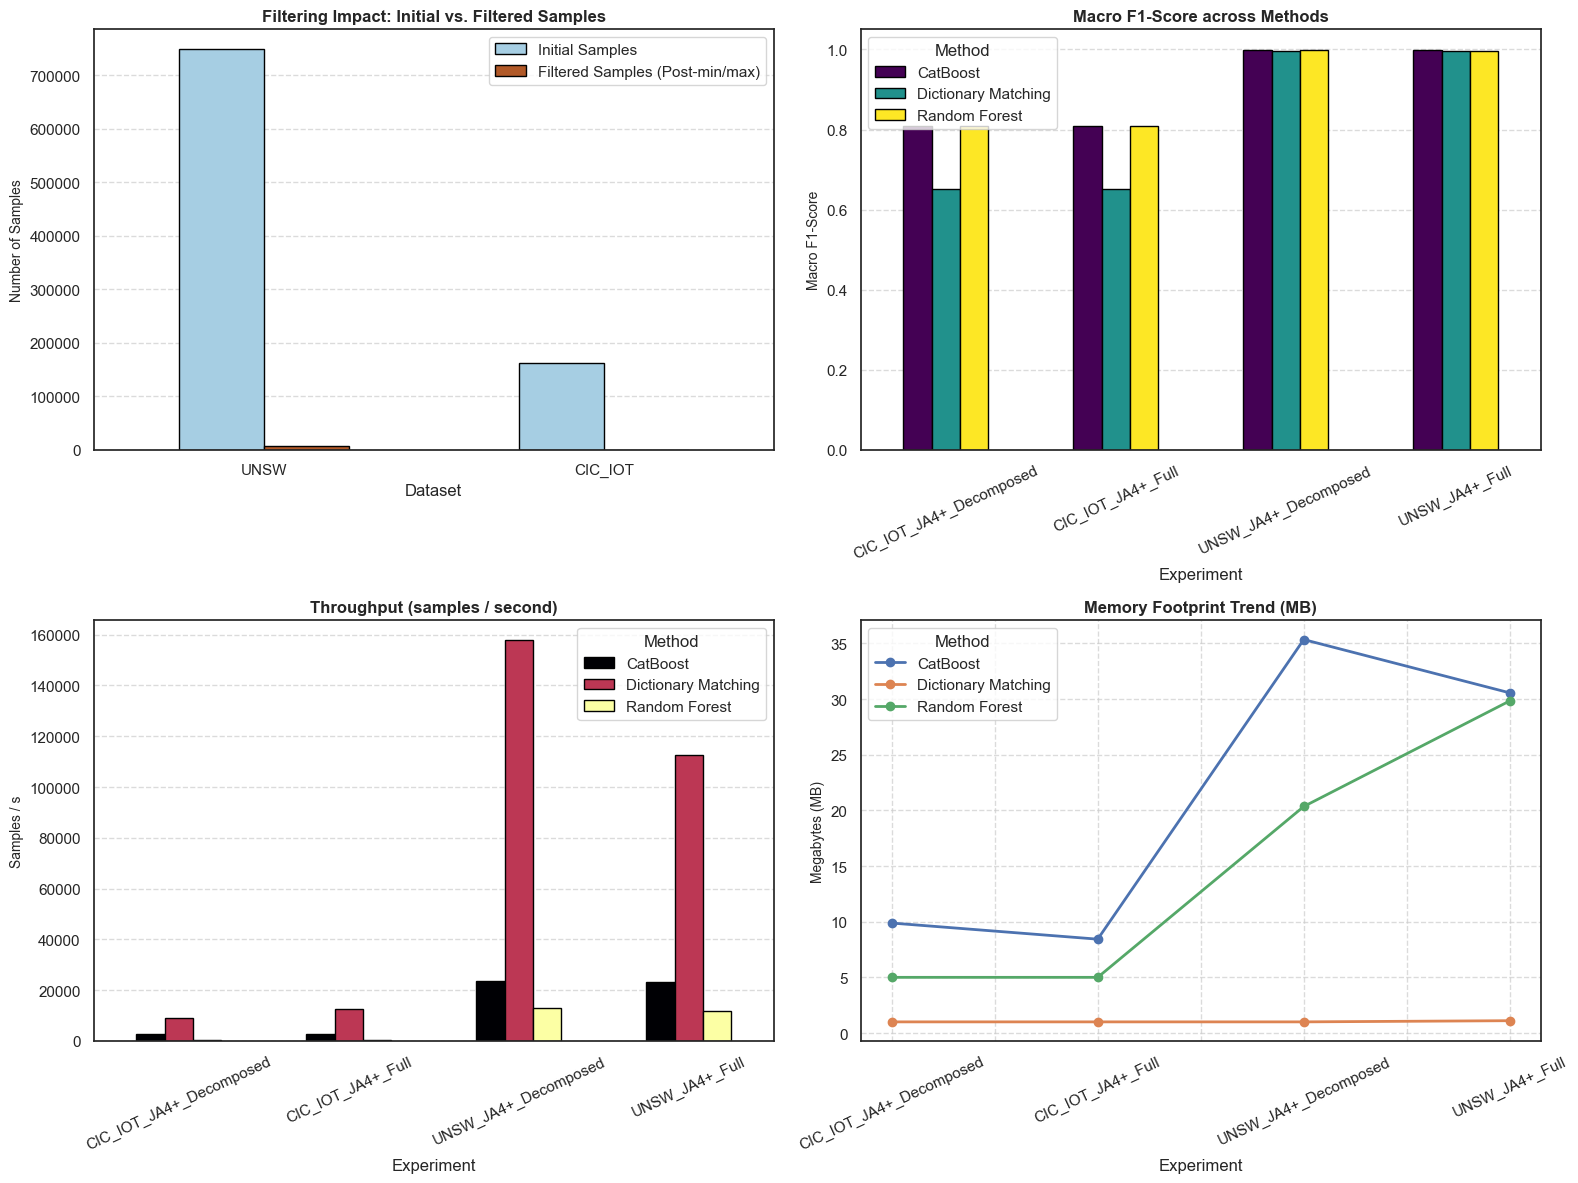

Advanced comparative plots saved to: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\Benchmark_Avanzado_Visualizacion.pdf


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Filtering Impact Bar Chart (Initial vs Filtered Samples)
df_audit.set_index("Dataset")[["Initial Samples", "Filtered Samples (Post-min/max)"]].plot(kind="bar", ax=axes[0, 0], colormap="Paired", edgecolor="black")
axes[0, 0].set_title("Filtering Impact: Initial vs. Filtered Samples", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Number of Samples", fontsize=10)
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.7)
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Macro F1-Score Comparison
pivot_f1 = df_summary.pivot(index="Experiment", columns="Method", values="F1-Score (Macro)")
pivot_f1.plot(kind="bar", ax=axes[0, 1], colormap="viridis", edgecolor="black")
axes[0, 1].set_title("Macro F1-Score across Methods", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Macro F1-Score", fontsize=10)
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.7)
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Throughput (samples/s)
pivot_tp = df_summary.pivot(index="Experiment", columns="Method", values="Throughput (samples/s)")
pivot_tp.plot(kind="bar", ax=axes[1, 0], colormap="inferno", edgecolor="black")
axes[1, 0].set_title("Throughput (samples / second)", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Samples / s", fontsize=10)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.7)
axes[1, 0].tick_params(axis="x", rotation=25)

# 4. Memory Footprint Trend
pivot_mem = df_summary.pivot(index="Experiment", columns="Method", values="Memory (MB)")
pivot_mem.plot(kind="line", marker='o', ax=axes[1, 1], linewidth=2)
axes[1, 1].set_title("Memory Footprint Trend (MB)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Megabytes (MB)", fontsize=10)
axes[1, 1].grid(True, linestyle="--", alpha=0.7)
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "Benchmark_Avanzado_Visualizacion.pdf")
plt.savefig(plot_path, format="pdf", bbox_inches="tight")
plt.show()
print(f"Advanced comparative plots saved to: {plot_path}")

### Individual Timing Figures

The following figures compare each method separately for training time, inference latency and throughput. The experiment labels distinguish datasets and Full versus Decomposed representations.

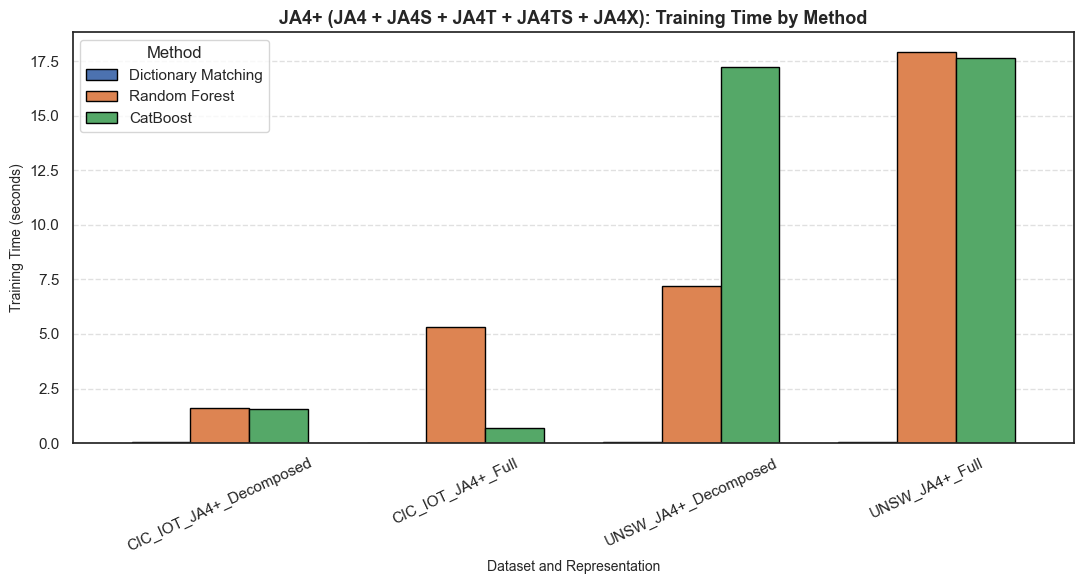

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4_PLUS_training_time.pdf


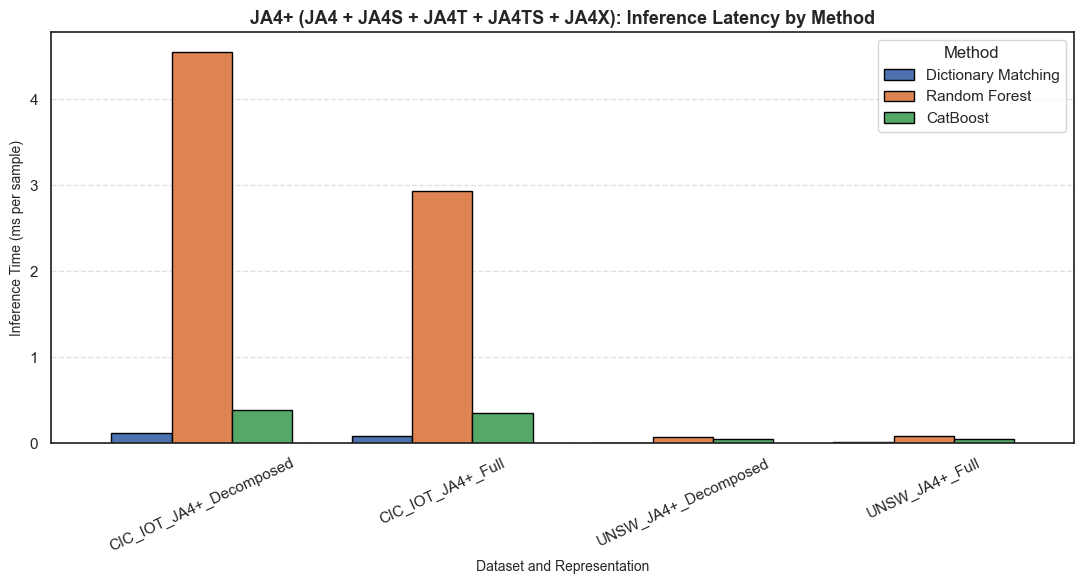

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4_PLUS_inference_latency.pdf


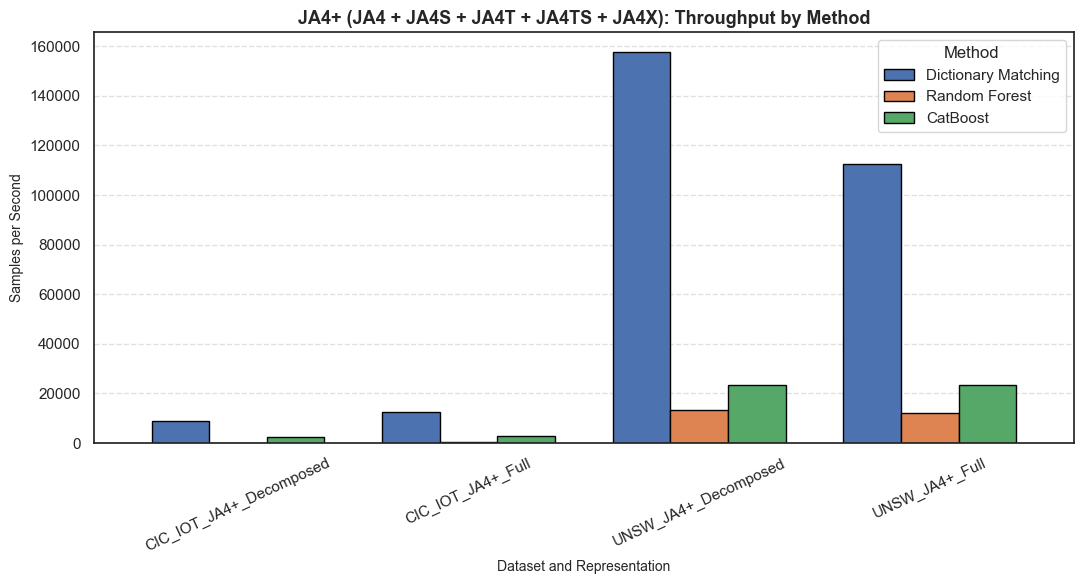

Saved: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\JA4_PLUS_throughput.pdf


In [19]:
import os
import matplotlib.pyplot as plt
import pandas as pd

COMBINATION_LABEL = "JA4+ (JA4 + JA4S + JA4T + JA4TS + JA4X)"
OUTPUT_TAG = "JA4_PLUS"
TIMING_OUTPUT_DIR = r"C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados"
os.makedirs(TIMING_OUTPUT_DIR, exist_ok=True)
timing_results = pd.DataFrame(all_global_results)
method_order = ["Dictionary Matching", "Random Forest", "CatBoost"]
timing_metrics = [
    ("Training Time (s)", "Training Time by Method", "Training Time (seconds)", "training_time"),
    ("Inference Time (ms/sample)", "Inference Latency by Method", "Inference Time (ms per sample)", "inference_latency"),
    ("Throughput (samples/s)", "Throughput by Method", "Samples per Second", "throughput")
]

# Re-run the benchmark definition and execution cells above if this fails after an edit.
missing_metrics = [metric for metric, *_ in timing_metrics if metric not in timing_results.columns]
if missing_metrics:
    raise KeyError(
        f"Missing columns in all_global_results: {missing_metrics}. "
        "Re-run the benchmark function cell and the dataset execution cell above, "
        "then re-run this cell."
    )

for metric, title, y_label, file_suffix in timing_metrics:
    timing_pivot = timing_results.pivot_table(
        index="Experiment", columns="Method", values=metric, aggfunc="mean"
    )
    timing_pivot = timing_pivot.reindex(columns=[method for method in method_order if method in timing_pivot.columns])
    ax = timing_pivot.plot(kind="bar", figsize=(11, 6), edgecolor="black", width=0.75)
    ax.set_title(f"{COMBINATION_LABEL}: {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Dataset and Representation", fontsize=10)
    ax.set_ylabel(y_label, fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(title="Method")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    figure_path = os.path.join(TIMING_OUTPUT_DIR, f"{OUTPUT_TAG}_{file_suffix}.pdf")
    ax.figure.savefig(figure_path, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)
    print(f"Saved: {figure_path}")

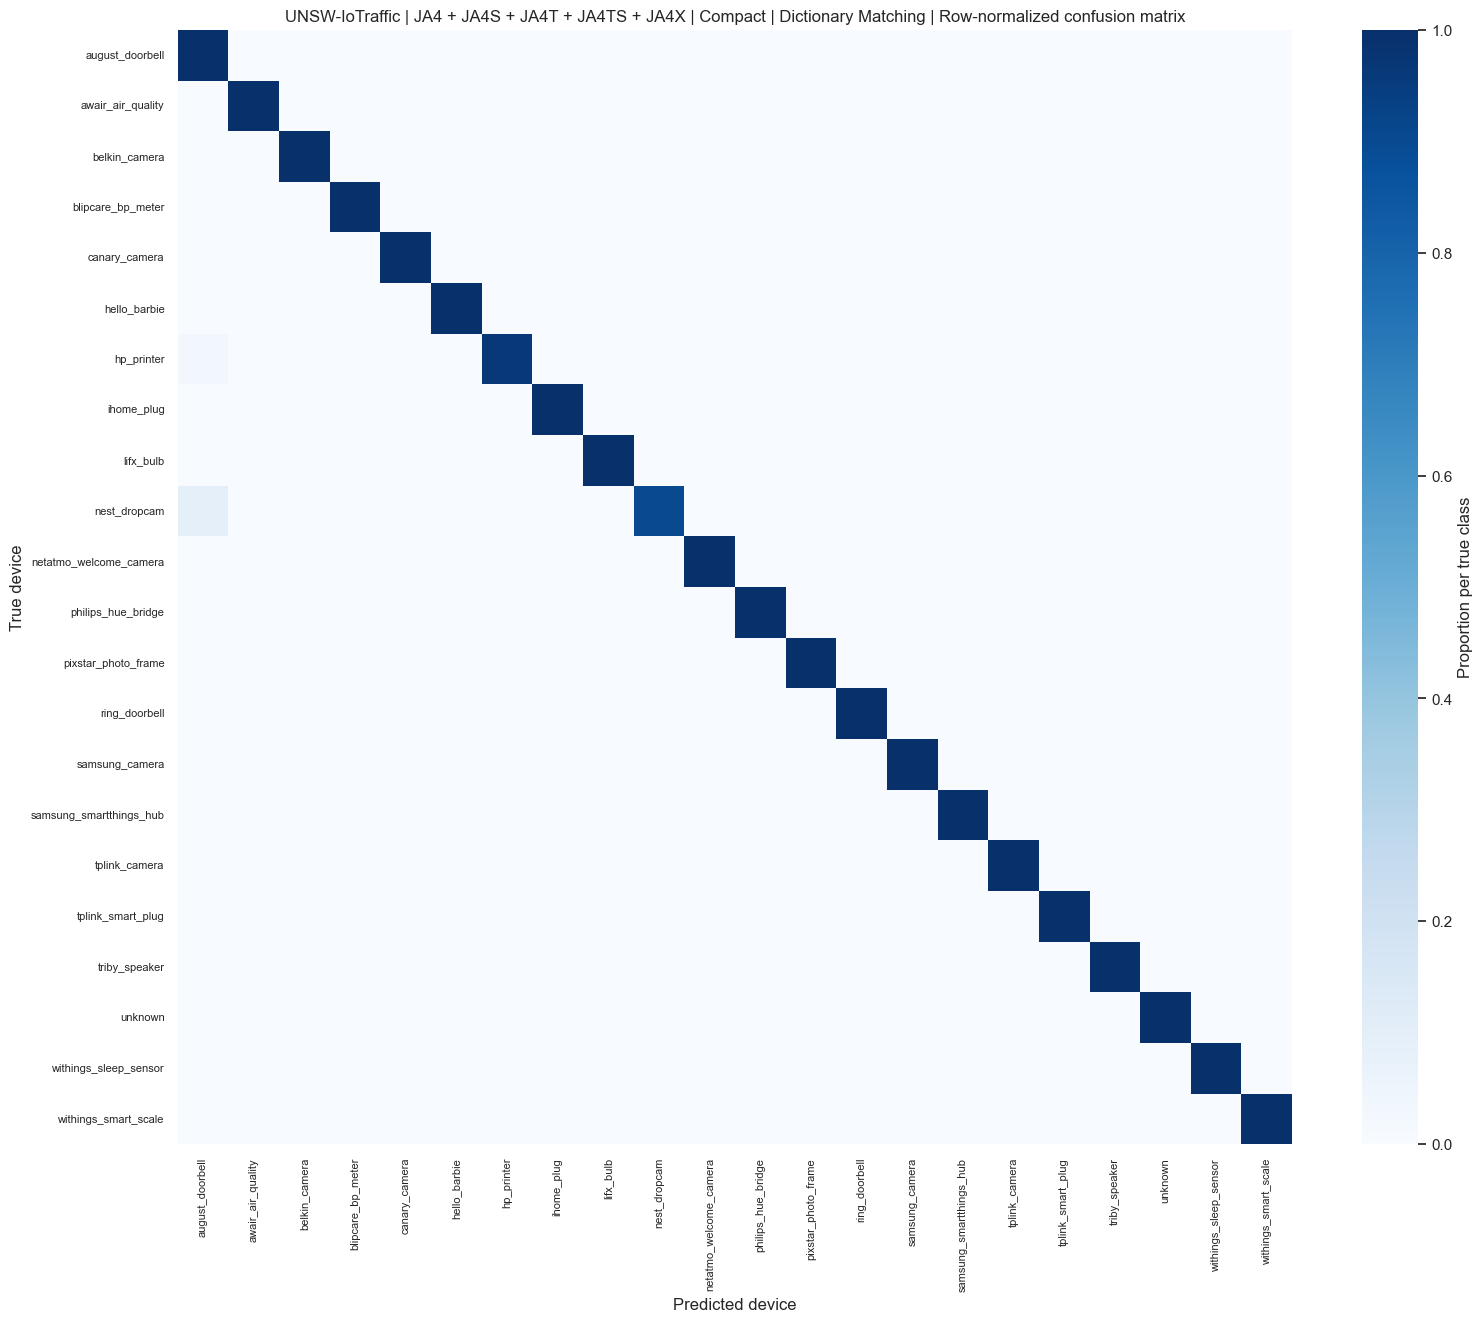

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_Dictionary_Matching_confusion_matrix.pdf


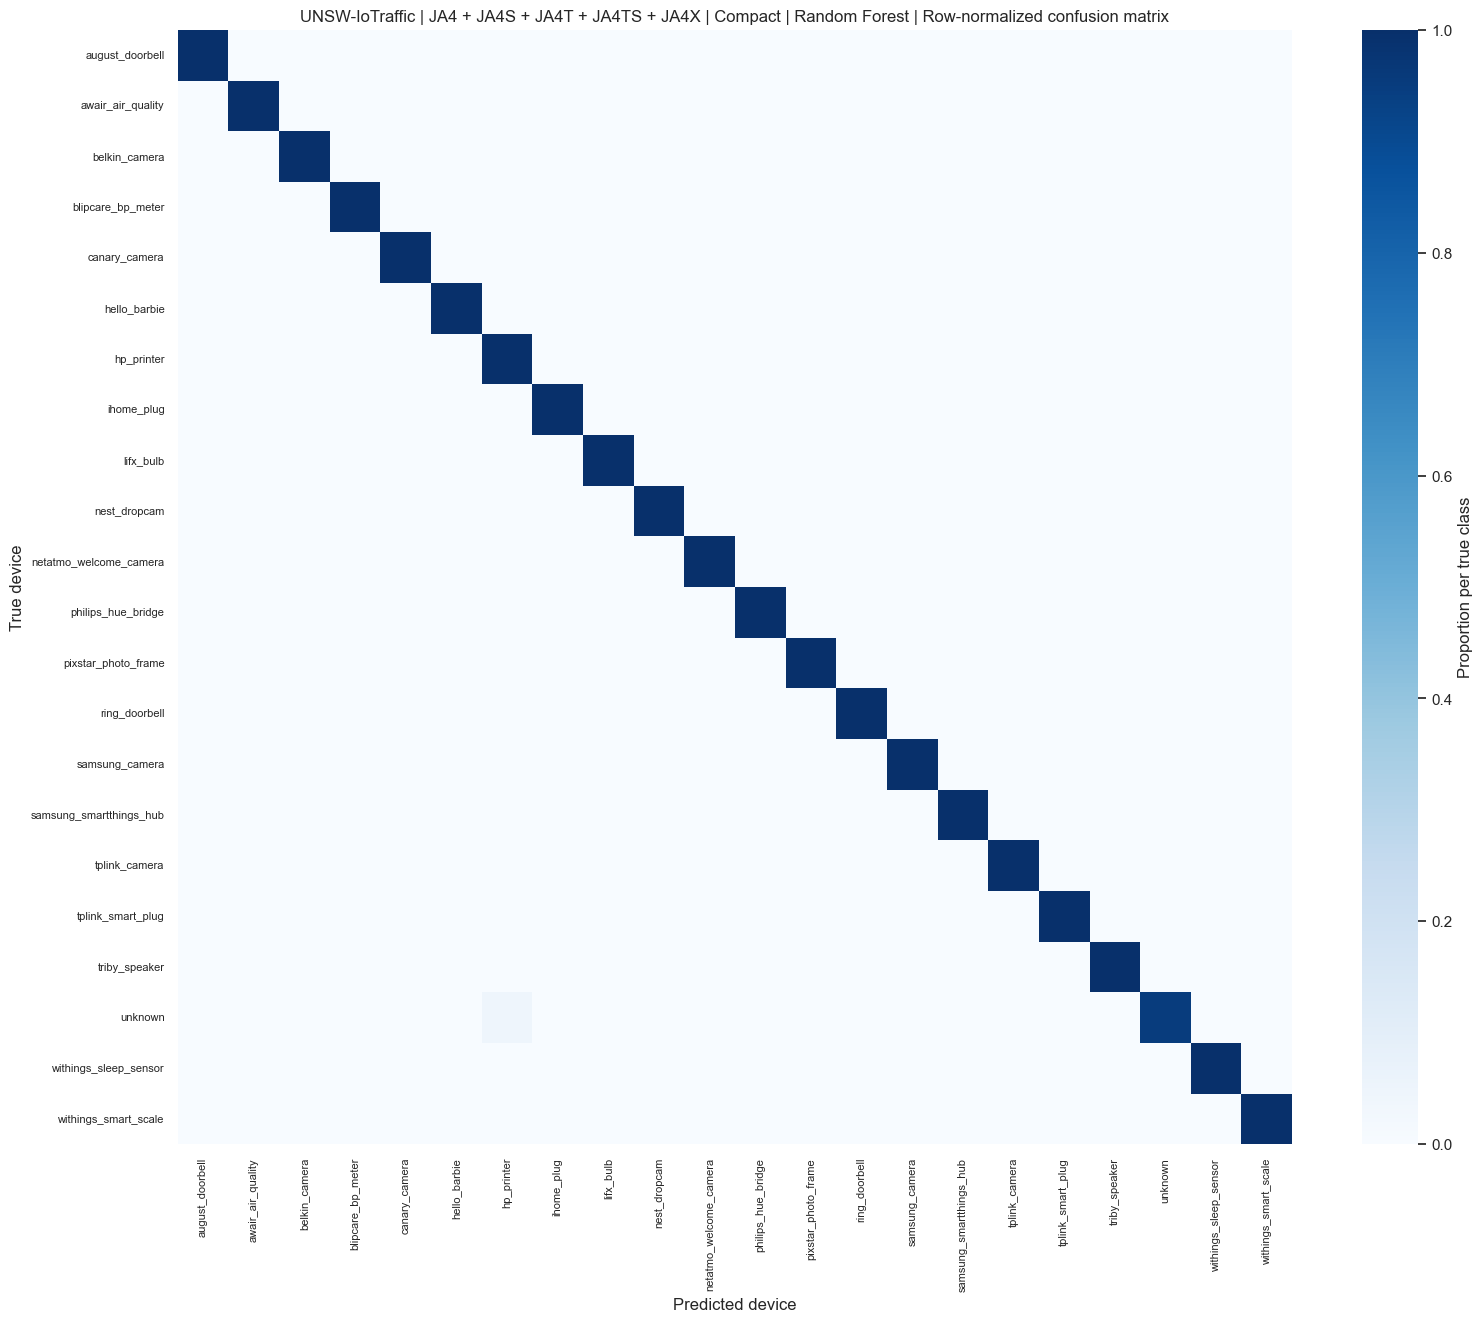

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_Random_Forest_confusion_matrix.pdf


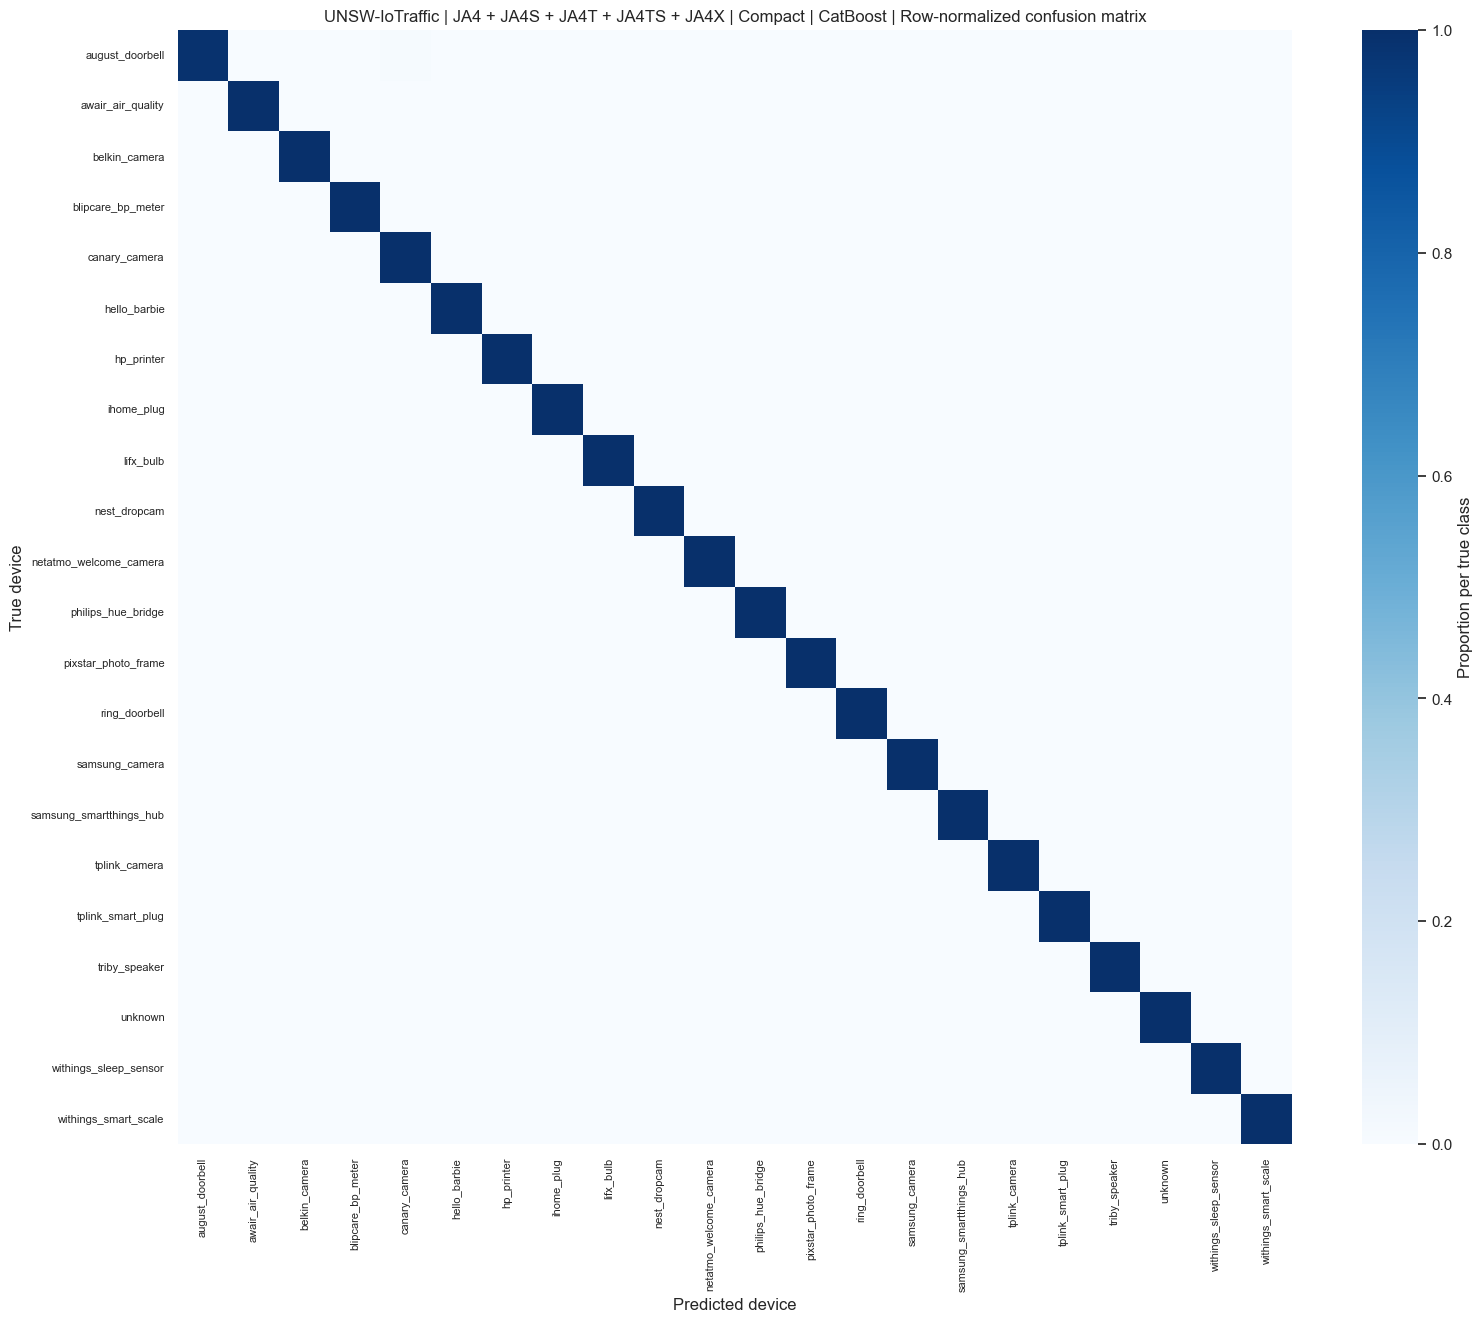

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_CatBoost_confusion_matrix.pdf


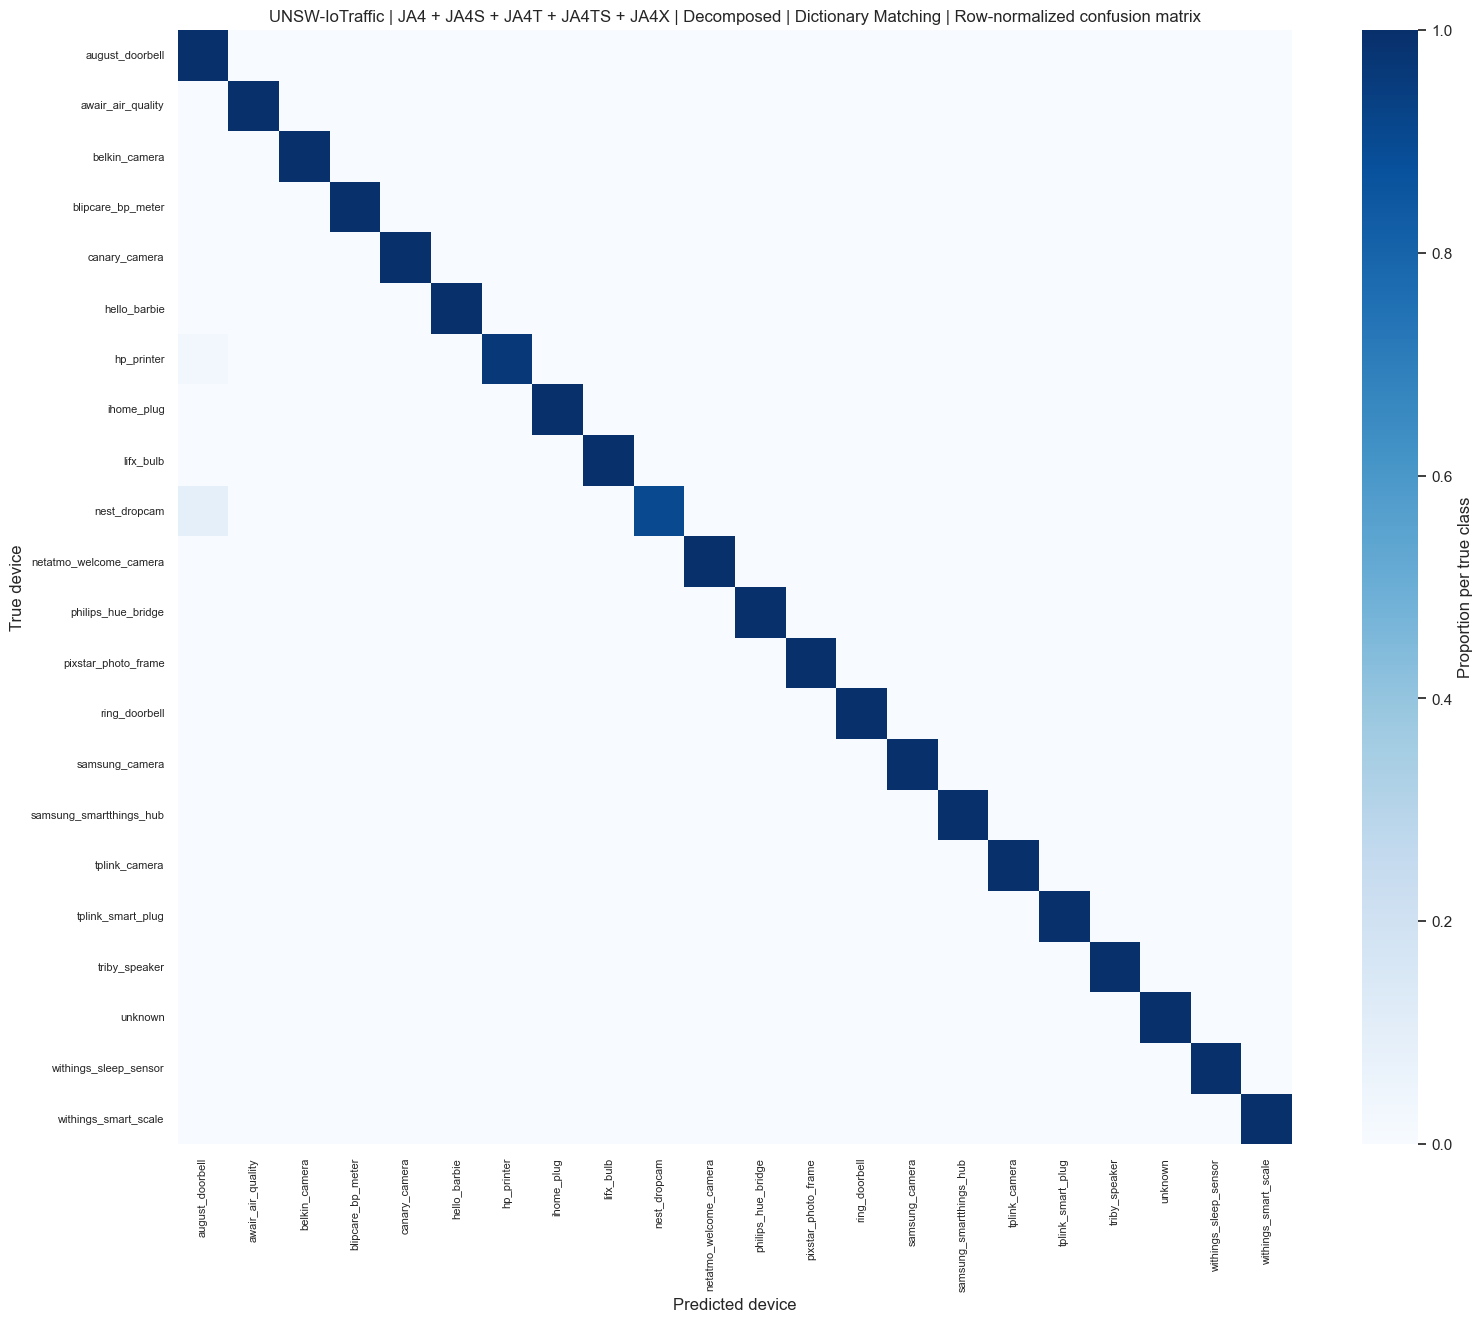

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_Dictionary_Matching_confusion_matrix.pdf


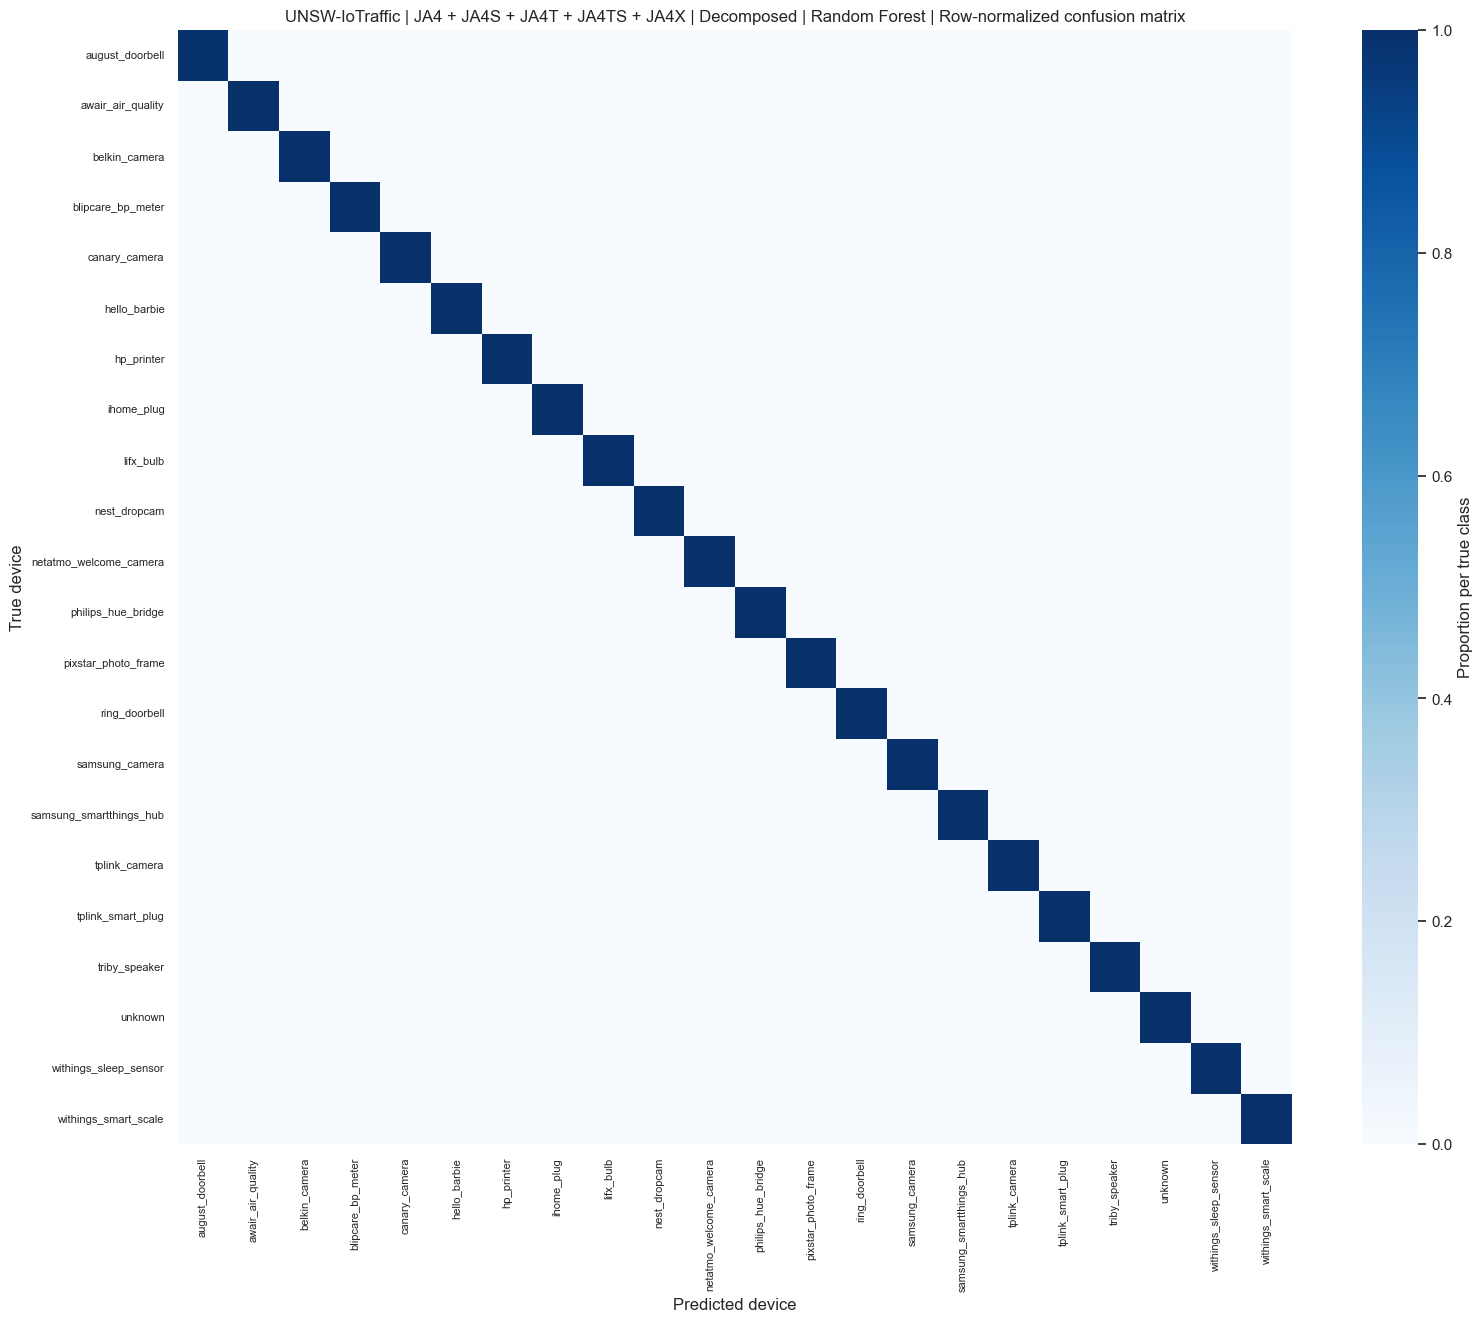

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_Random_Forest_confusion_matrix.pdf


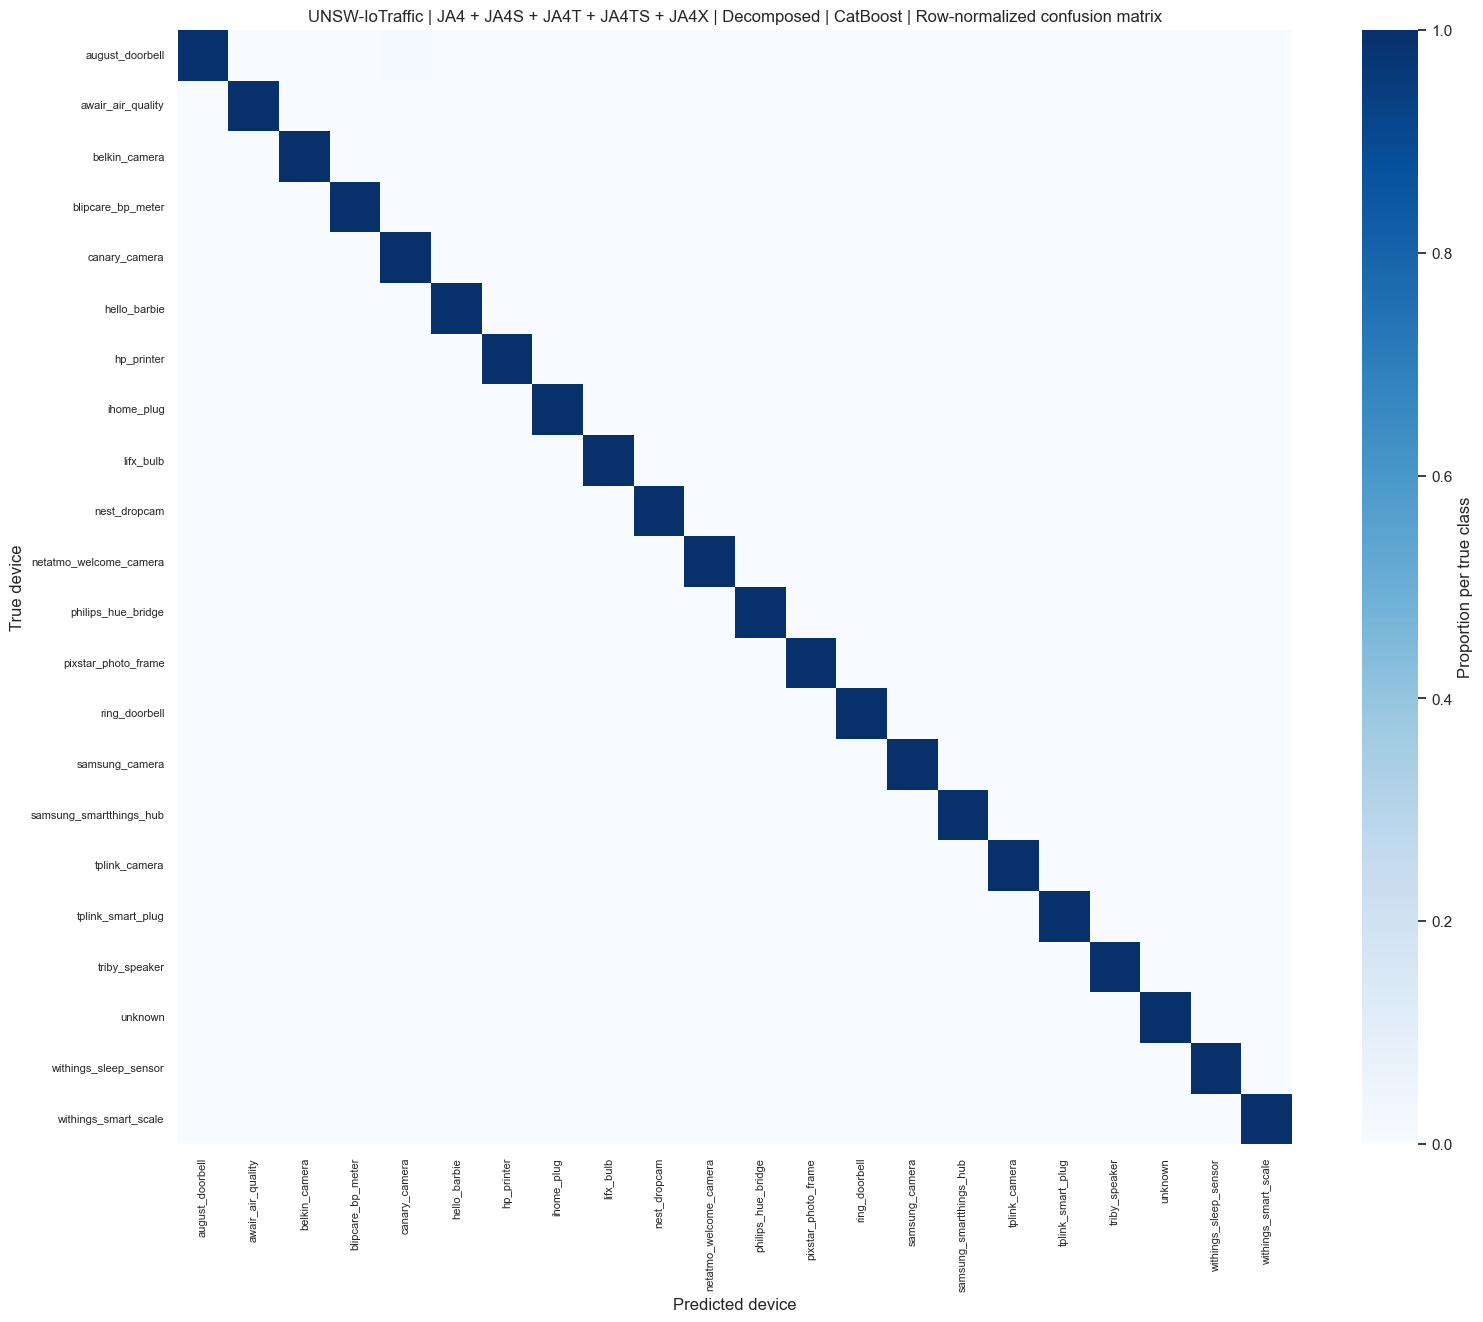

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_CatBoost_confusion_matrix.pdf


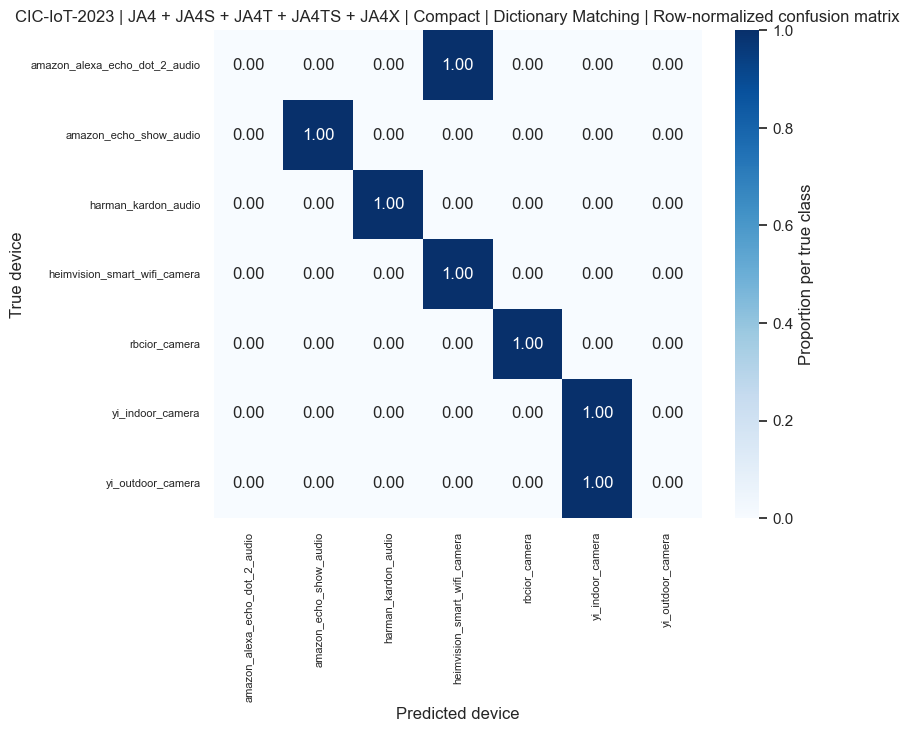

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_Dictionary_Matching_confusion_matrix.pdf


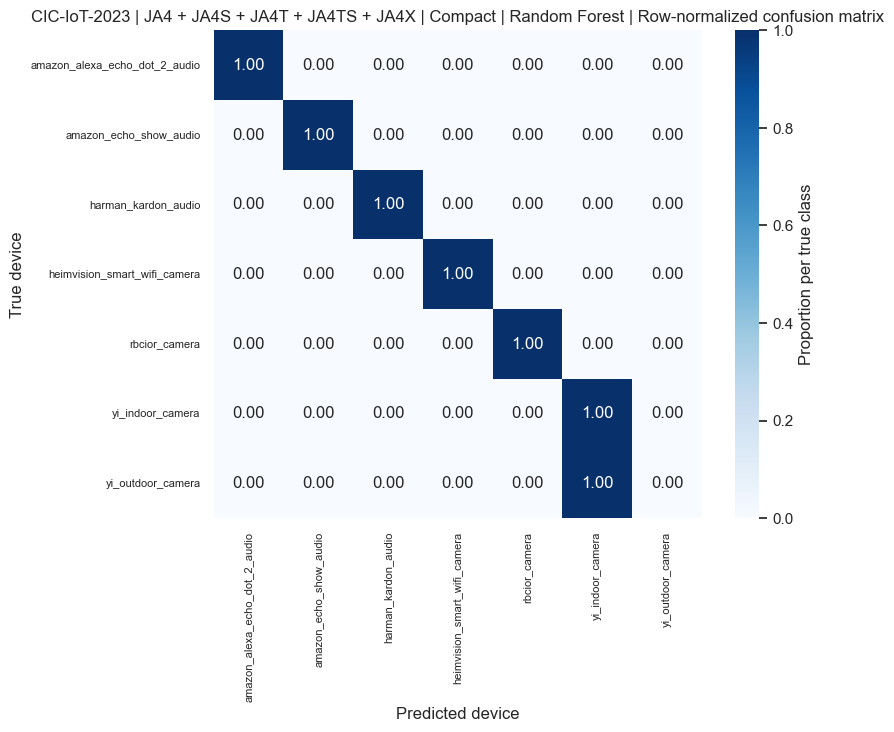

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_Random_Forest_confusion_matrix.pdf


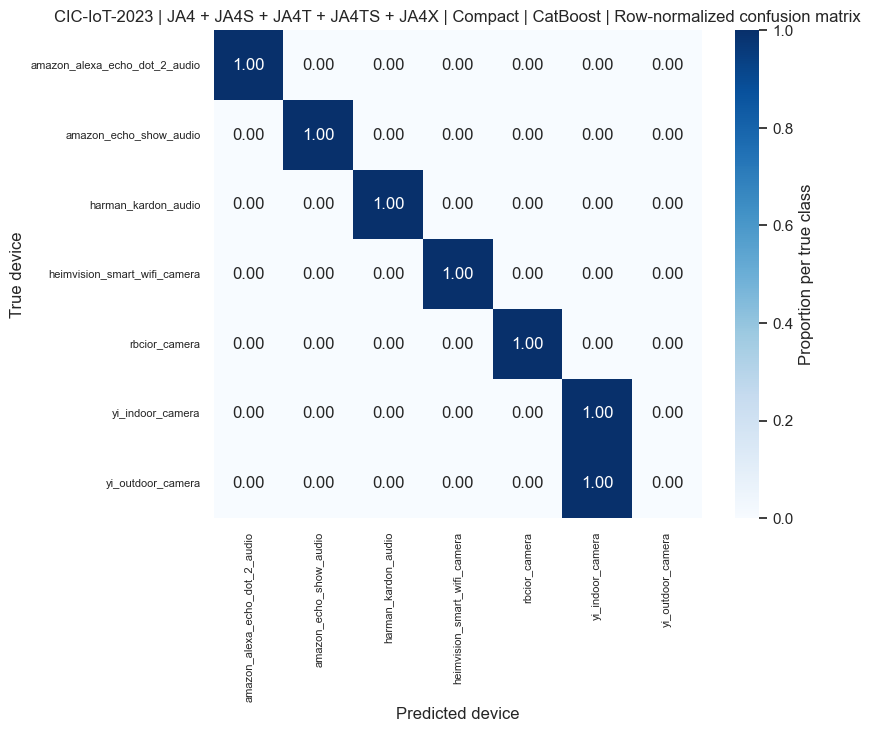

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_CatBoost_confusion_matrix.pdf


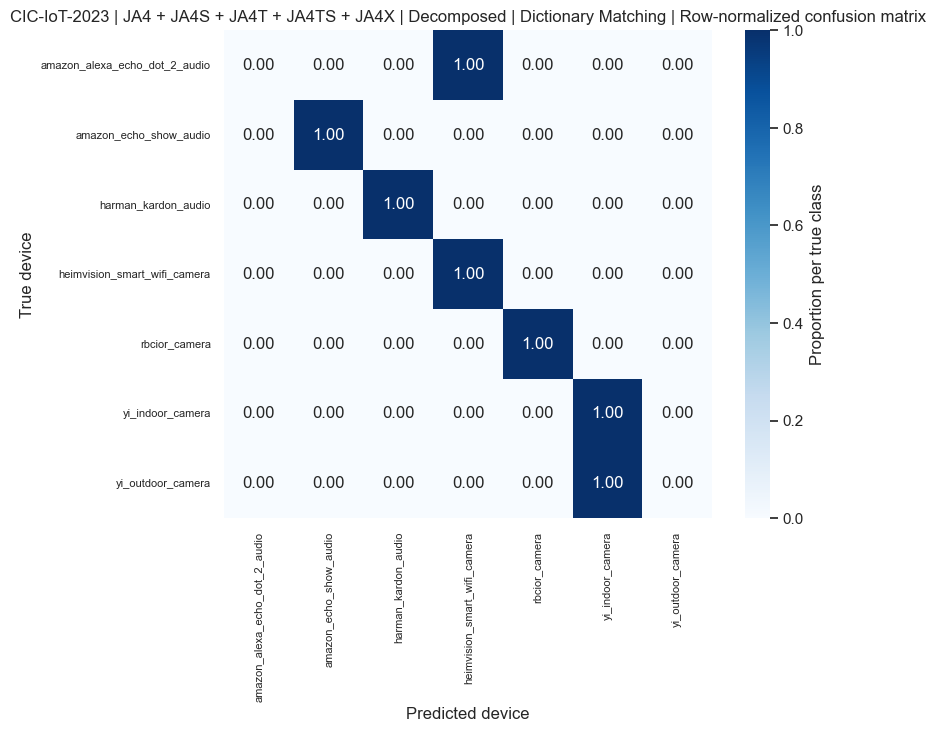

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_Dictionary_Matching_confusion_matrix.pdf


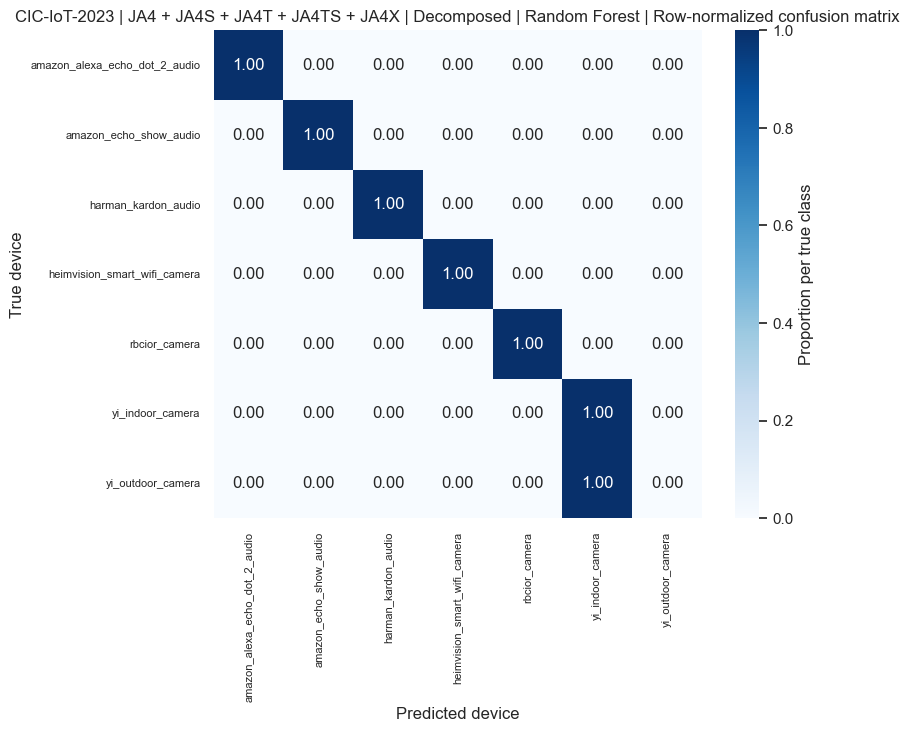

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_Random_Forest_confusion_matrix.pdf


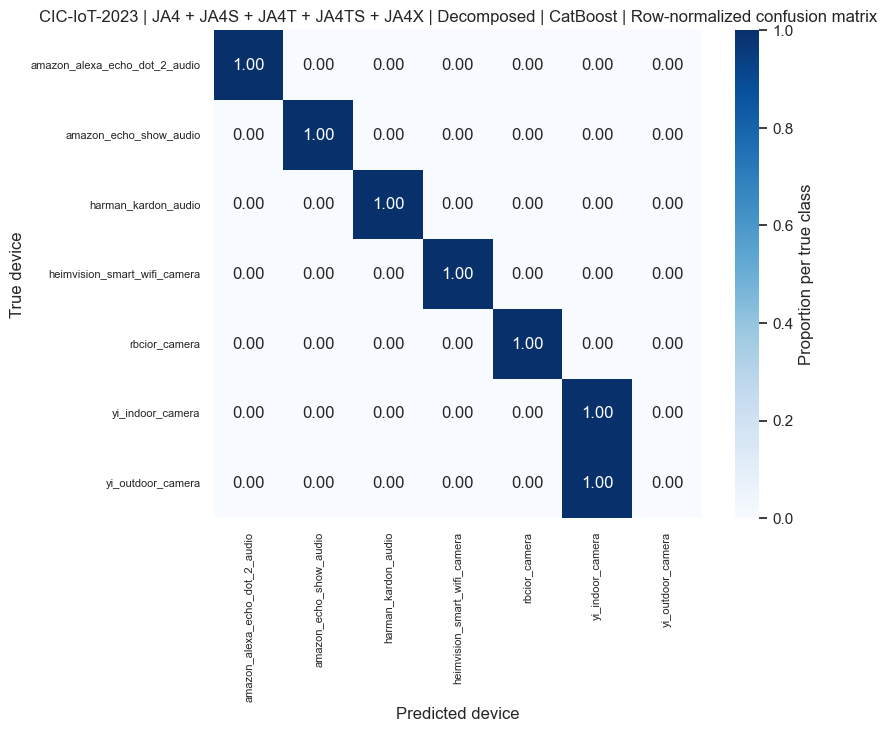

Saved confusion matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_CatBoost_confusion_matrix.pdf
EXPLORATORY AUDIT & FILTERING ANALYSIS: JA4+ | UNSW
[Fingerprint Stats] Total valid samples: 745924
[Fingerprint Stats] Unique JA4+ fingerprints: 145 (0.02%)
[Fingerprint Stats] Repeated JA4+ fingerprints: 745779 (99.98%)

--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---


,device_name,ja4,ja4s,ja4t,ja4ts,ja4x,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,...,ja4ts_option_list,ja4ts_mss,ja4ts_scale,ja4ts_num_options,ja4ts_has_timestamp,ja4ts_has_sack,ja4ts_has_window_scale,ja4x_issuer_hash,ja4x_subject_hash,ja4x_extensions_hash
0,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,t100100_0035_bc98f8e001b5,4380_2-4-8-1-3_1460_4,8190_2-1-3_1460_6,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,...,2-1-3,1460,6,3,0,0,1,53aaa0ff,44a2873e,6ea8df877ef2
1,Hello_Barbie,t10d550500_59f835f43fe7_db1f1d781382,t100100_0035_bc98f8e001b5,4380_2-4-8-1-3_1460_4,8190_2-1-3_1460_6,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,...,2-1-3,1460,6,3,0,0,1,53aaa0ff,44a2873e,6ea8df877ef2
2,Hello_Barbie,t10d550400_59f835f43fe7_990b54203475,t100000_002f_000000000000,4380_2-4-8-1-3_1460_4,8190_2-1-3_1460_6,53aaa0ff_44a2873e_6ea8df877ef2,t,10,d,55,...,2-1-3,1460,6,3,0,0,1,53aaa0ff,44a2873e,6ea8df877ef2


[Audit Summary] Retained Classes: 22/22 | Final Samples: 6533
--------------------------------------------------------------------------------


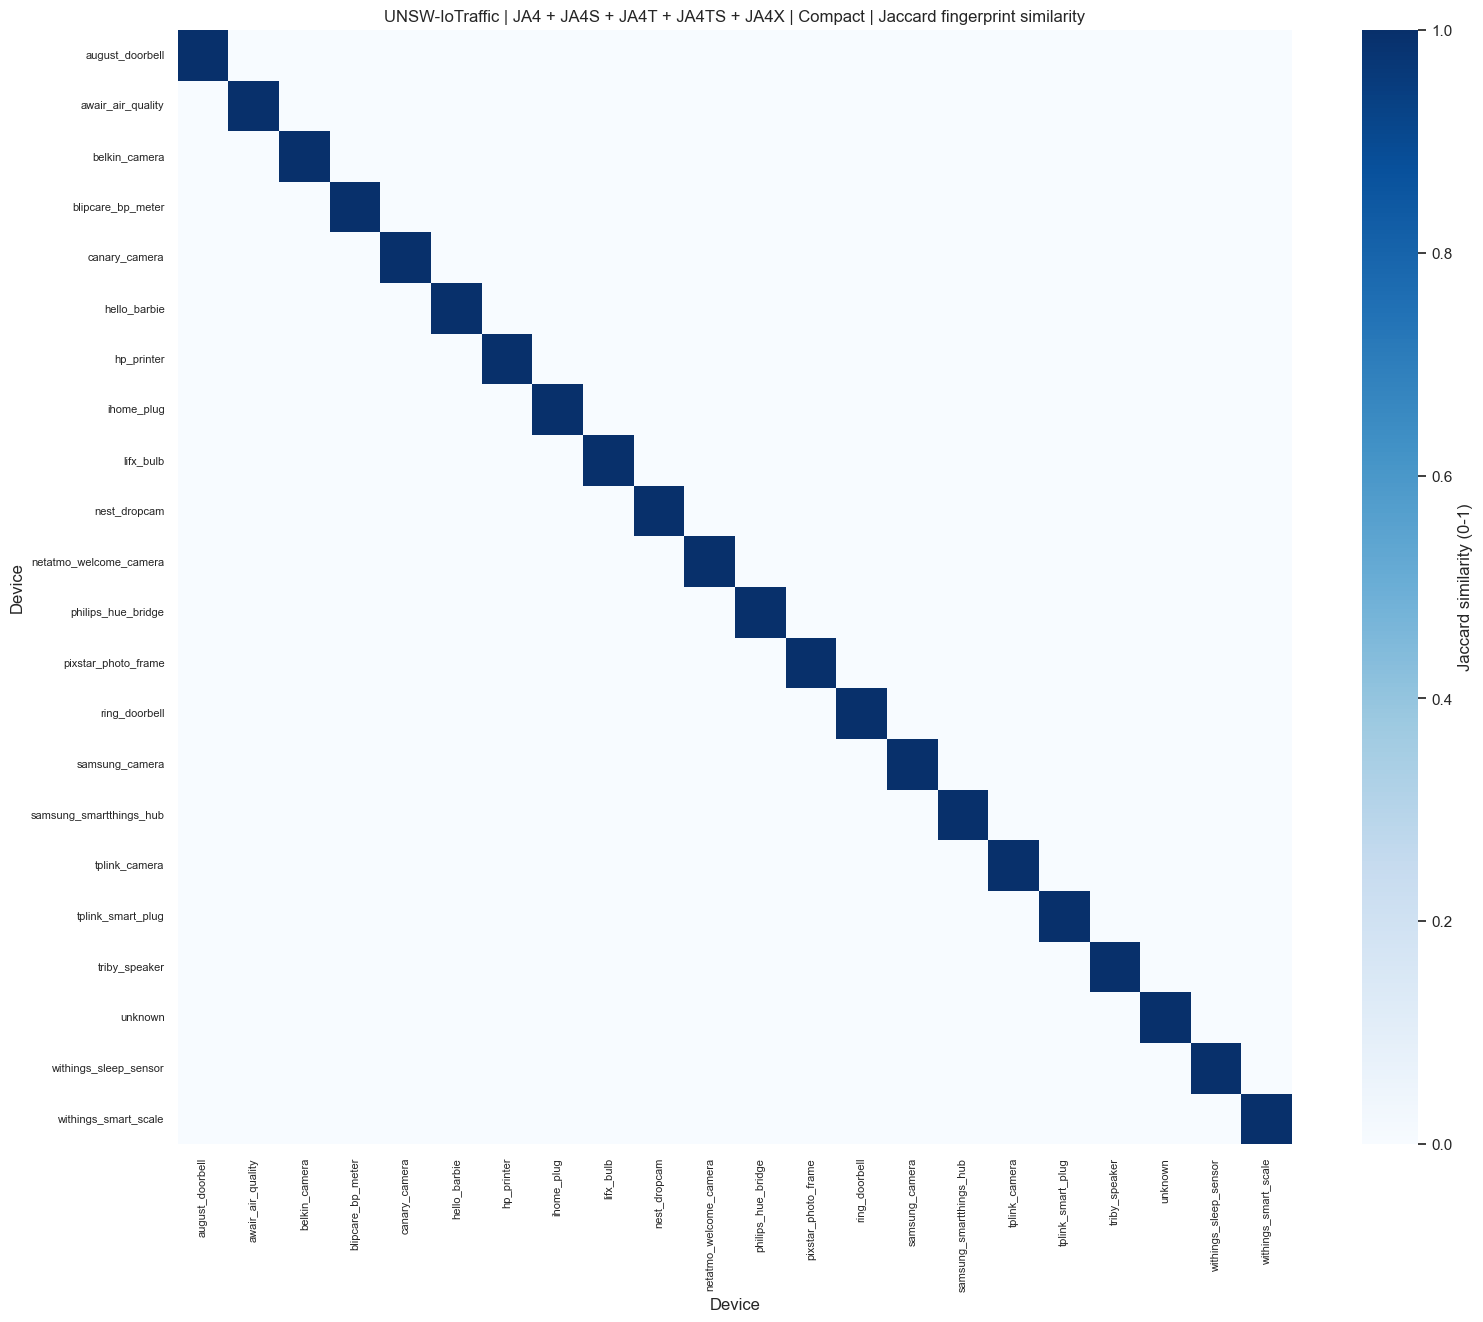

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_jaccard_similarity.pdf


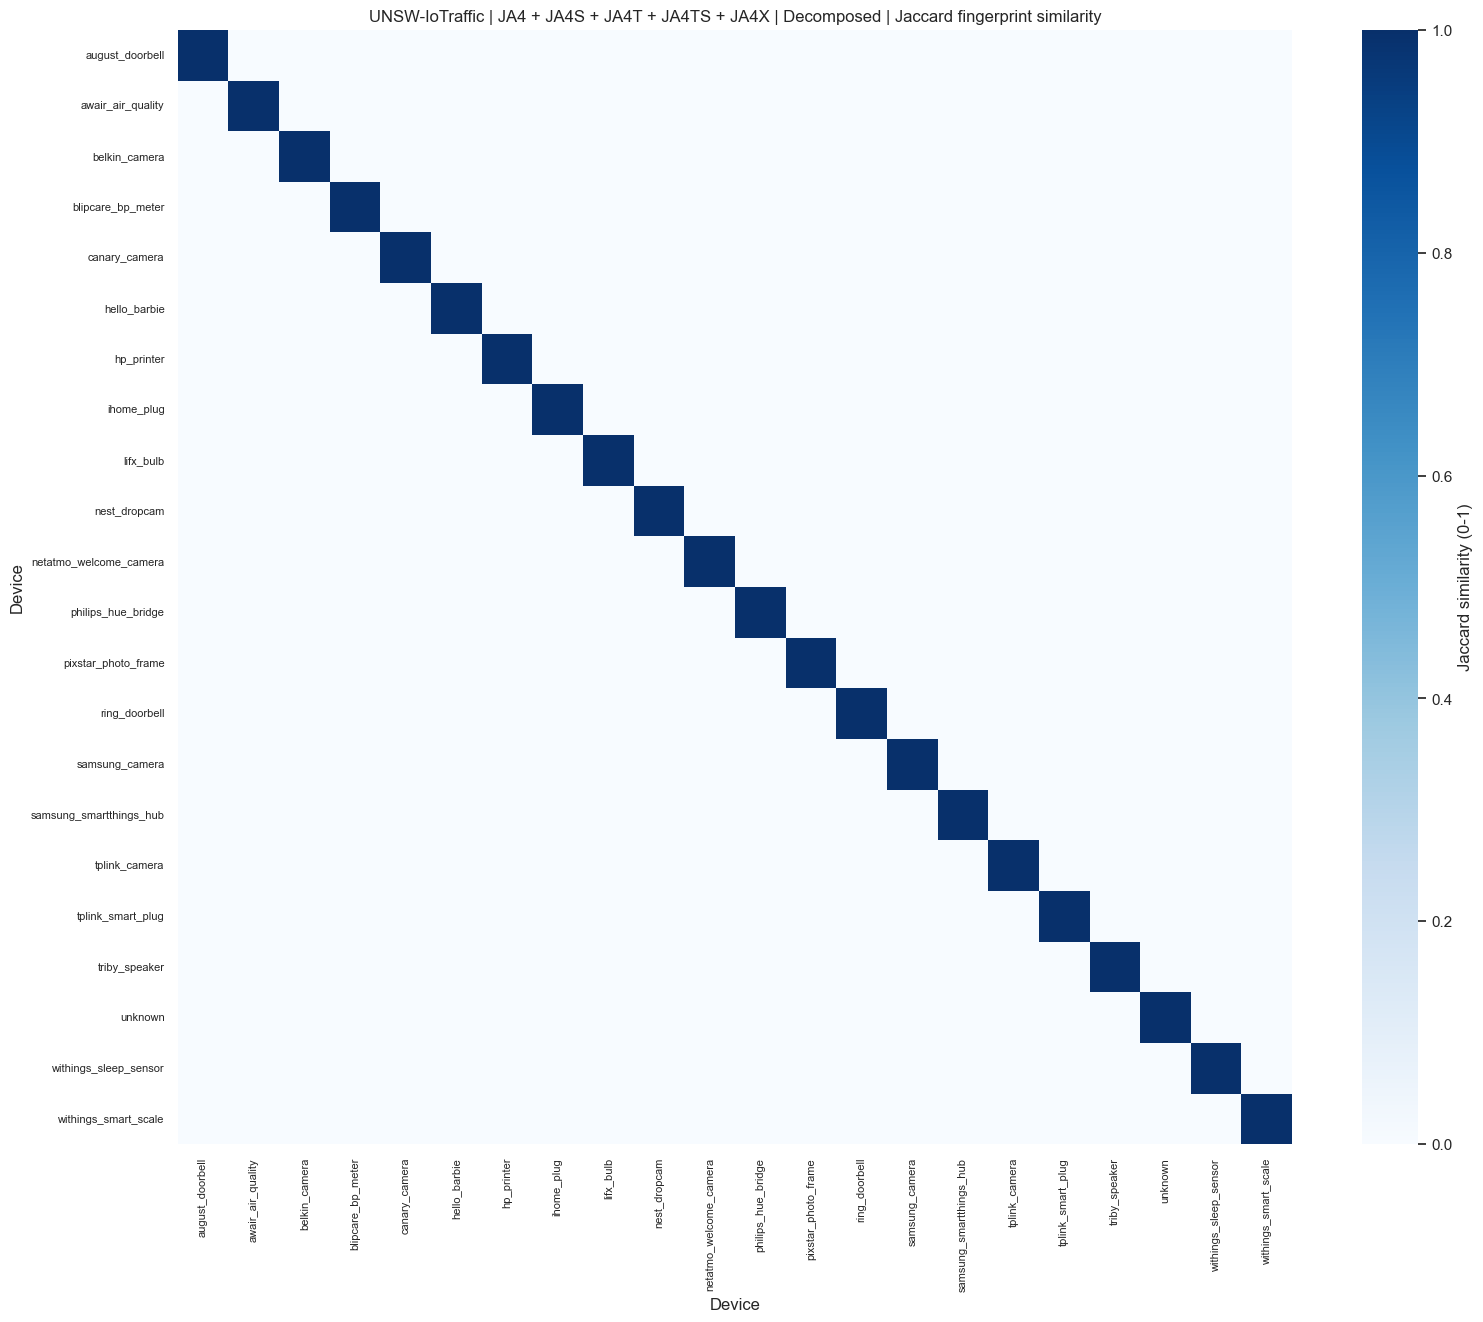

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\UNSW-IoTraffic_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_jaccard_similarity.pdf
EXPLORATORY AUDIT & FILTERING ANALYSIS: JA4+ | CIC_IOT
[Fingerprint Stats] Total valid samples: 103
[Fingerprint Stats] Unique JA4+ fingerprints: 18 (17.48%)
[Fingerprint Stats] Repeated JA4+ fingerprints: 85 (82.52%)

--- SAMPLE FULL & DECOMPOSED REPRESENTATION EXAMPLES ---


,device_name,ja4,ja4s,ja4t,ja4ts,ja4x,ja4_protocol,ja4_tls_version,ja4_sni_type,ja4_n_ciphers,...,ja4ts_option_list,ja4ts_mss,ja4ts_scale,ja4ts_num_options,ja4ts_has_timestamp,ja4ts_has_sack,ja4ts_has_window_scale,ja4x_issuer_hash,ja4x_subject_hash,ja4x_extensions_hash
394,Rbcior_Camera,t12d040600_39def8a70f78_9b994c9d23f8,t120300_c027_7815a3cc5eb2,14600_2-4-8-1-3_1460_3,65535_2-4-8-1-3_1460_9,f1bb6372_f1bb6372_000000000000,t,12,d,4,...,2-4-8-1-3,1460,9,5,1,1,1,f1bb6372,f1bb6372,000000000000
6039,Harman_Kardon_Audio,t12i0507h2_2af0c3a5c862_e0fb7d0a714d,t120300_c02f_5935512bb26a,14600_2-4-8-1-3_1460_4,28960_2-4-8-1-3_1460_5,02ace205_02ace205_1c314e97029a,t,12,i,5,...,2-4-8-1-3,1460,5,5,1,1,1,02ace205,02ace205,1c314e97029a
6110,SmartThings_Hub,t13d311000_e8f1e7e78f70_5ac7197df9d2,t120300_c02f_7a0270e617ef,29200_2-4-8-1-3_1460_5,26847_2-4-8-1-3_1460_12,0bc7f0af_0bc7f0af_000000000000,t,13,d,31,...,2-4-8-1-3,1460,12,5,1,1,1,0bc7f0af,0bc7f0af,000000000000


[Audit Summary] Retained Classes: 7/52 | Final Samples: 93
--------------------------------------------------------------------------------


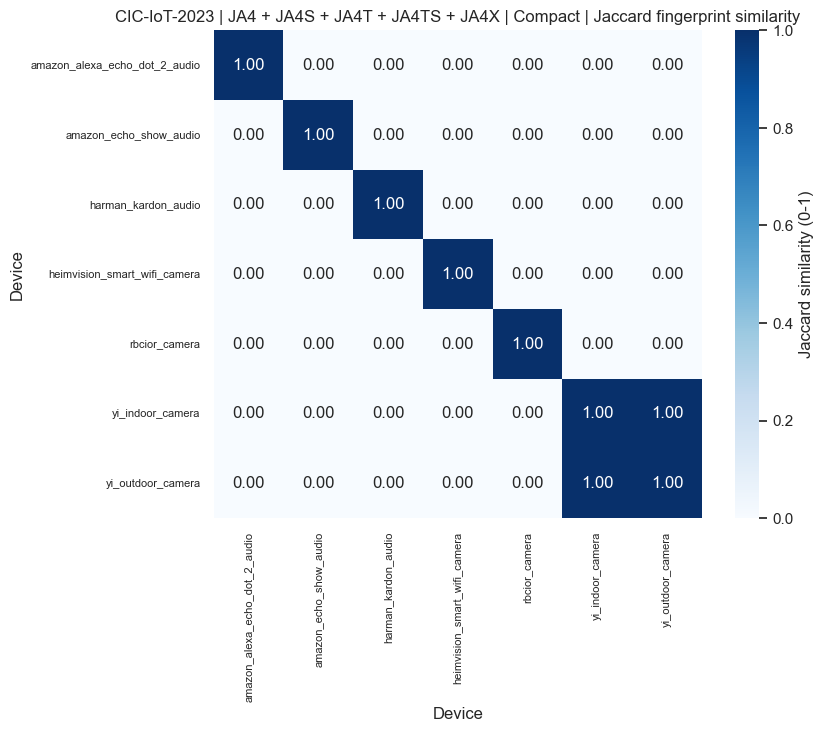

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Compact_jaccard_similarity.pdf


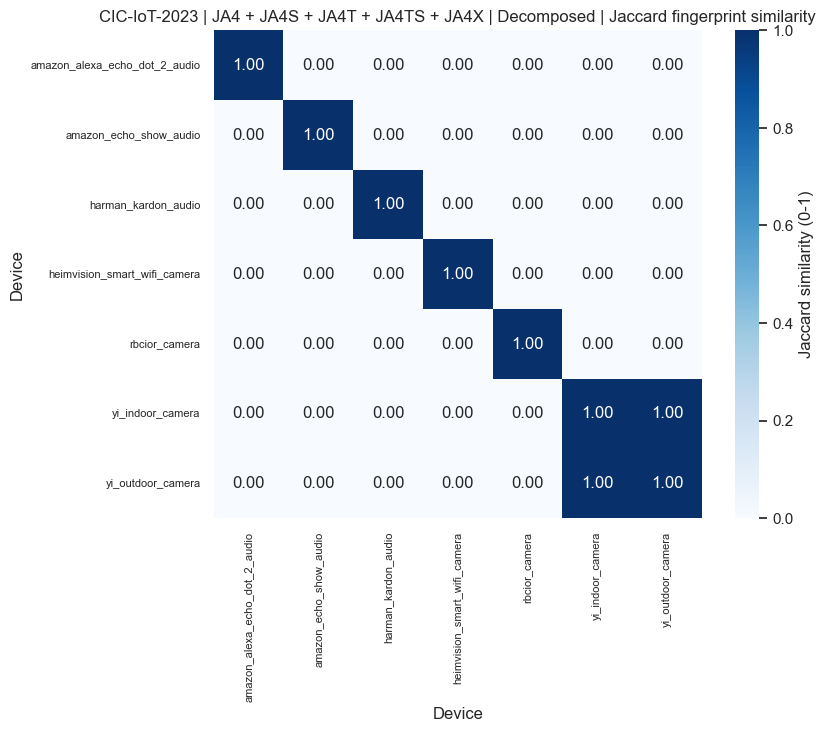

Saved similarity matrix: C:\Users\gemma\Desktop\TFG_GemmaBeatrizVate\UNSW-IoTraffic\Resultados_Consolidados\similarity_and_confusion_matrices\CIC-IoT-2023_JA4_plus_JA4S_plus_JA4T_plus_JA4TS_plus_JA4X_Decomposed_jaccard_similarity.pdf
Generated 12 normalized confusion matrices and 4 Jaccard similarity matrices as individual PDFs.


In [21]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

if "benchmark_prediction_records" not in globals() or not benchmark_prediction_records:
    raise RuntimeError("Run the dataset benchmark cell before generating matrices.")

matrix_output_dir = os.path.join(OUTPUT_DIR, "similarity_and_confusion_matrices")
os.makedirs(matrix_output_dir, exist_ok=True)
latest_records = {record["Experiment"]: record for record in benchmark_prediction_records}

fingerprint_label = " + ".join(feature.upper() for feature in FULL_FEATURES)


def make_file_stem(value):
    return str(value).replace("+", "plus").replace(" ", "_").replace("/", "_").replace(":", "").replace("(", "").replace(")", "")


sns.set_theme(style="white")
confusion_matrix_count = 0
for record in latest_records.values():
    class_names = np.asarray(record["class_names"])
    class_labels = np.arange(len(class_names))
    true_labels = np.asarray(record["y_true"])
    experiment_name = record["Experiment"]
    dataset_name = "CIC-IoT-2023" if experiment_name.startswith("CIC_IOT") else "UNSW-IoTraffic"
    representation_name = "Decomposed" if experiment_name.endswith("_Decomposed") else "Compact"

    for algorithm_name, predicted_labels in record["predictions"].items():
        raw_matrix = confusion_matrix(true_labels, np.asarray(predicted_labels), labels=class_labels)
        row_totals = raw_matrix.sum(axis=1, keepdims=True)
        normalized_matrix = np.divide(
            raw_matrix,
            row_totals,
            out=np.zeros(raw_matrix.shape, dtype=float),
            where=row_totals != 0,
        )
        side_length = max(9, min(20, 4 + 0.55 * len(class_names)))
        figure, axis = plt.subplots(figsize=(side_length, side_length * 0.82))
        sns.heatmap(
            normalized_matrix,
            ax=axis,
            cmap="Blues",
            vmin=0,
            vmax=1,
            square=True,
            annot=len(class_names) <= 12,
            fmt=".2f",
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={"label": "Proportion per true class"},
        )
        axis.set_title(f"{dataset_name} | {fingerprint_label} | {representation_name} | {algorithm_name} | Row-normalized confusion matrix")
        axis.set_xlabel("Predicted device")
        axis.set_ylabel("True device")
        axis.tick_params(axis="x", labelrotation=90, labelsize=8)
        axis.tick_params(axis="y", labelrotation=0, labelsize=8)
        figure.tight_layout()
        file_stem = make_file_stem(f"{dataset_name}_{fingerprint_label}_{representation_name}_{algorithm_name}_confusion_matrix")
        figure_path = os.path.join(matrix_output_dir, f"{file_stem}.pdf")
        figure.savefig(figure_path, bbox_inches="tight")
        plt.show()
        plt.close(figure)
        confusion_matrix_count += 1
        print(f"Saved confusion matrix: {figure_path}")

similarity_matrix_count = 0
for dataset_key, dataset_config in DATASETS_CONFIG.items():
    cleaned_dataset, _ = analyze_and_clean_dataset(
        dataset_config["path"],
        dataset_config["min_samples"],
        dataset_config["max_samples"],
        dataset_name=dataset_key,
    )
    dataset_name = "CIC-IoT-2023" if dataset_key == "CIC_IOT" else "UNSW-IoTraffic"
    class_names = sorted(cleaned_dataset[TARGET_COL].unique())

    for representation_name, feature_columns in [
        ("Compact", FULL_FEATURES),
        ("Decomposed", DECOMPOSED_FEATURES),
    ]:
        fingerprints_by_class = {}
        for class_name in class_names:
            class_rows = cleaned_dataset.loc[cleaned_dataset[TARGET_COL] == class_name, feature_columns]
            fingerprints_by_class[class_name] = set(
                map(tuple, class_rows.fillna("unknown").astype(str).to_numpy())
            )

        similarity_matrix = np.eye(len(class_names), dtype=float)
        for row_index, first_class in enumerate(class_names):
            for column_index in range(row_index + 1, len(class_names)):
                second_class = class_names[column_index]
                first_fingerprints = fingerprints_by_class[first_class]
                second_fingerprints = fingerprints_by_class[second_class]
                union_size = len(first_fingerprints | second_fingerprints)
                similarity = (
                    len(first_fingerprints & second_fingerprints) / union_size
                    if union_size
                    else 0.0
                )
                similarity_matrix[row_index, column_index] = similarity
                similarity_matrix[column_index, row_index] = similarity

        side_length = max(9, min(20, 4 + 0.55 * len(class_names)))
        figure, axis = plt.subplots(figsize=(side_length, side_length * 0.82))
        sns.heatmap(
            similarity_matrix,
            ax=axis,
            cmap="Blues",
            vmin=0,
            vmax=1,
            square=True,
            annot=len(class_names) <= 12,
            fmt=".2f",
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={"label": "Jaccard similarity (0-1)"},
        )
        axis.set_title(f"{dataset_name} | {fingerprint_label} | {representation_name} | Jaccard fingerprint similarity")
        axis.set_xlabel("Device")
        axis.set_ylabel("Device")
        axis.tick_params(axis="x", labelrotation=90, labelsize=8)
        axis.tick_params(axis="y", labelrotation=0, labelsize=8)
        figure.tight_layout()
        file_stem = make_file_stem(f"{dataset_name}_{fingerprint_label}_{representation_name}_jaccard_similarity")
        figure_path = os.path.join(matrix_output_dir, f"{file_stem}.pdf")
        figure.savefig(figure_path, bbox_inches="tight")
        plt.show()
        plt.close(figure)
        similarity_matrix_count += 1
        print(f"Saved similarity matrix: {figure_path}")

print(f"Generated {confusion_matrix_count} normalized confusion matrices and {similarity_matrix_count} Jaccard similarity matrices as individual PDFs.")